# DSP391M - Báo Cáo Tiến Độ 3
## Đánh giá ảnh hưởng của độ phân giải đến phát hiện khuôn mặt trên ChokePoint

**Sinh viên:** Vũ Hải Minh - HE194098  
**Dataset:** ChokePoint, giao thức Portal 1 indoor frontal  
**Mô hình:** YOLOv5n, YOLOv8n, YOLOv12n, SCRFD  
**Trọng tâm nghiên cứu:** xác định mức độ phân giải vận hành mà tại đó hệ thống camera an ninh vẫn phát hiện khuôn mặt ổn định trong khi chi phí tính toán được giảm đáng kể.


## 1. Mục tiêu nghiên cứu và phạm vi báo cáo

Câu hỏi trung tâm của đề tài không chỉ là mô hình nào có độ chính xác cao nhất. Vấn đề quan trọng hơn là tìm **điểm cắt độ phân giải**: khung hình camera có thể được giảm xuống đến mức nào trước khi chất lượng phát hiện khuôn mặt không còn đủ tin cậy cho một pipeline nhận diện/xác thực khuôn mặt.

Báo cáo này tách rõ hai tầng:

- **Phát hiện khuôn mặt:** định vị vùng mặt trong ảnh camera toàn khung.
- **Nhận diện/xác thực khuôn mặt:** xác định danh tính sau khi mặt đã được phát hiện, crop và căn chỉnh.

Report 3 tập trung vào tầng phát hiện vì chất lượng crop đầu vào quyết định độ ổn định của tầng nhận diện phía sau. Các kết quả trong báo cáo được lưu thành bảng CSV/JSON và hình ảnh để dùng lại trực tiếp trong paper.


## 2. Nguyên tắc trực quan hóa áp dụng trong báo cáo

Phần visualization được thiết kế lại theo các nguyên tắc sau:

- Mỗi biểu đồ trả lời một câu hỏi nghiên cứu cụ thể, tránh gom quá nhiều thông tin vào một hình.
- Với dữ liệu phân loại như tên mô hình, dùng màu khác hue và marker khác nhau để dễ phân biệt khi in đen trắng.
- Với dữ liệu số dạng ma trận như threshold-resolution, dùng colormap tuần tự có độ sáng thay đổi đều; tránh rainbow/jet vì dễ gây hiểu sai.
- Với đường cong cutoff, dùng hình lớn, marker rõ, ngưỡng tham chiếu và vùng khuyến nghị để người đọc thấy ngay điểm vận hành.
- Các biểu đồ dùng trong paper được lưu tự động vào thư mục `chokepoint_data/modeling/report3_figures`.

Các lựa chọn này dựa trên khuyến nghị từ tài liệu Seaborn về palette: hue phù hợp cho category, luminance phù hợp cho numeric data, và biểu đồ quá nhiều màu/legend sẽ khó đọc. Matplotlib cũng khuyến nghị dùng colormap có tính perceptual hơn và cảnh báo các colormap như jet/rainbow có độ sáng biến thiên không đều. ColorBrewer được dùng như một tham chiếu về palette an toàn hơn cho in ấn và colorblind-safe.


In [1]:
from pathlib import Path
import json
import subprocess
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image as PILImage, ImageDraw
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning, module="pandas.core.computation.expressions")
warnings.filterwarnings("ignore", message="Specified provider 'CUDAExecutionProvider'.*")
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive.*")

PROJECT_ROOT = Path(".").resolve()
MODELING_ROOT = PROJECT_ROOT / "chokepoint_data" / "modeling"
FIGURE_DIR = MODELING_ROOT / "report3_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

for old_figure in list(FIGURE_DIR.glob("report3_*.png")) + list(FIGURE_DIR.glob("report3_*.pdf")):
    old_figure.unlink()

MANIFEST_PATH = MODELING_ROOT / "chokepoint_p1_indoor_frontal_manifest.csv"
FULL_BENCHMARK_PATH = MODELING_ROOT / "benchmark_full_eval_gpu_yolo_both_scrfd_sample5676.csv"
FIXED_BENCHMARK_PATH = FULL_BENCHMARK_PATH
FULL_BENCHMARK_JSON_PATH = MODELING_ROOT / "benchmark_full_eval_gpu_yolo_both_scrfd_sample5676.json"
FIXED_PRED_PATH = MODELING_ROOT / "benchmark_full_eval_gpu_yolo_both_scrfd_predictions_sample5676.csv"
FIXED_SAMPLE_PATH = MODELING_ROOT / "benchmark_full_eval_gpu_yolo_both_scrfd_sample5676_manifest.csv"
RESOLUTION_BENCHMARK_PATH = MODELING_ROOT / "benchmark_resolution_full_eval_gpu_yolov5n_yolov8n_yolov12n_scrfd_sample5676.csv"
RESOLUTION_BENCHMARK_JSON_PATH = MODELING_ROOT / "benchmark_resolution_full_eval_gpu_yolov5n_yolov8n_yolov12n_scrfd_sample5676.json"
RESOLUTION_PRED_PATH = MODELING_ROOT / "benchmark_resolution_full_eval_gpu_yolov5n_yolov8n_yolov12n_scrfd_predictions_sample5676.csv"
YOLO_DATASET_SUMMARY_PATH = MODELING_ROOT / "yolo_face_dataset" / "dataset_summary.json"
YOLO_TRAINING_SUMMARY_PATH = MODELING_ROOT / "yolo_finetuned_full_gpu_weights" / "training_summary.json"

PRIMARY_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50
SAVED_FIGURES = []

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.unicode_minus": False,
    "figure.dpi": 120,
    "savefig.dpi": 240,
    "axes.titlesize": 18,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "legend.title_fontsize": 12,
    "axes.titleweight": "bold",
})

MODEL_ORDER = ["YOLOv5n-FT", "YOLOv8n-FT", "YOLOv12n-FT", "SCRFD"]
MODEL_COLORS = {
    "YOLOv5n-FT": "#D55E00",
    "YOLOv8n-FT": "#009E73",
    "YOLOv12n-FT": "#CC79A7",
    "SCRFD": "#0072B2",
}
MODEL_MARKERS = {
    "YOLOv5n-FT": "s",
    "YOLOv8n-FT": "^",
    "YOLOv12n-FT": "D",
    "SCRFD": "o",
}


def save_figure(fig, name: str) -> None:
    png_path = FIGURE_DIR / f"report3_{name}.png"
    pdf_path = FIGURE_DIR / f"report3_{name}.pdf"
    fig.savefig(png_path, bbox_inches="tight", facecolor="white")
    fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
    SAVED_FIGURES.append({
        "Tên hình": f"report3_{name}",
        "PNG": str(png_path.relative_to(PROJECT_ROOT)),
        "PDF": str(pdf_path.relative_to(PROJECT_ROOT)),
    })


def run_if_missing(expected_outputs, command, label: str) -> None:
    expected_outputs = [Path(path) for path in expected_outputs]
    missing = [path for path in expected_outputs if not path.exists()]
    if missing:
        print(f"Chạy {label}: thiếu {len(missing)} artifact.")
        subprocess.run(command, check=True)
    else:
        print(f"Bỏ qua {label}: artifact full GPU đã tồn tại.")


def style_axis(ax, grid_axis: str = "y") -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, axis=grid_axis, alpha=0.25)


def annotate_last_points(ax, data, x_col, y_col, label_col, color_col=None, x_offset=6) -> None:
    for _, row in data.iterrows():
        color = row[color_col] if color_col else "black"
        ax.annotate(
            str(row[label_col]),
            xy=(row[x_col], row[y_col]),
            xytext=(x_offset, 0),
            textcoords="offset points",
            va="center",
            fontsize=10,
            color=color,
        )


print("Project root:", PROJECT_ROOT)
print("Modeling root:", MODELING_ROOT)
print("Figure output:", FIGURE_DIR)


D:\Anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Project root: D:\Admin\Download\DSP391m
Modeling root: D:\Admin\Download\DSP391m\chokepoint_data\modeling
Figure output: D:\Admin\Download\DSP391m\chokepoint_data\modeling\report3_figures


## 3. Fine-tune YOLO trên bbox ChokePoint

Các mô hình YOLO được fine-tune trước khi benchmark để so sánh công bằng hơn với SCRFD. Bbox dùng để train là bbox suy ra từ landmark mắt trong ChokePoint. Phiên bản full GPU của report sử dụng toàn bộ protocol P1 indoor frontal:

- Train split: toàn bộ `train_dev` với 6,035 ảnh.
- Validation/benchmark split: toàn bộ `eval` với 5,676 ảnh.
- Epochs: 20.
- Image size: 640.
- Device: CUDA trong env `cvlface` nếu khả dụng.
- Output weights: `chokepoint_data/modeling/yolo_finetuned_full_gpu_weights/*_face.pt`.

Script train sẽ tự bỏ qua nếu weights full GPU đã tồn tại. Việc benchmark được thực hiện trên full eval split, không dùng sample rút gọn.


In [2]:
run_if_missing(
    [YOLO_DATASET_SUMMARY_PATH],
    [
        sys.executable,
        str(MODELING_ROOT / "prepare_yolo_face_dataset.py"),
        "--output-root", str(MODELING_ROOT / "yolo_face_dataset"),
        "--train-limit", "0",
        "--val-limit", "0",
    ],
    "chuẩn bị YOLO dataset full",
)


Bỏ qua chuẩn bị YOLO dataset full: artifact full GPU đã tồn tại.


In [3]:
run_if_missing(
    [
        MODELING_ROOT / "yolo_finetuned_full_gpu_weights" / "yolov5n_face.pt",
        MODELING_ROOT / "yolo_finetuned_full_gpu_weights" / "yolov8n_face.pt",
        MODELING_ROOT / "yolo_finetuned_full_gpu_weights" / "yolov12n_face.pt",
        YOLO_TRAINING_SUMMARY_PATH,
    ],
    [
        sys.executable,
        str(MODELING_ROOT / "train_yolo_face_models.py"),
        "--models", "yolov5n,yolov8n,yolov12n",
        "--epochs", "20",
        "--imgsz", "640",
        "--batch", "-1",
        "--workers", "2",
        "--patience", "10",
        "--project", str(MODELING_ROOT / "yolo_finetune_full_gpu_runs"),
        "--weights-dir", str(MODELING_ROOT / "yolo_finetuned_full_gpu_weights"),
    ],
    "fine-tune YOLO full GPU",
)


Bỏ qua fine-tune YOLO full GPU: artifact full GPU đã tồn tại.


## 4. Quy trình benchmark

Sau fine-tune, report chạy hai benchmark chính bằng YOLO fine-tuned và SCRFD trên toàn bộ eval split:

- `run_yolo_scrfd_benchmark.py --sample-mode eval --eval-sample 0`: benchmark cố định trên 5,676 frame eval.
- `run_resolution_benchmark.py --sample-mode eval --eval-sample 0`: benchmark theo nhiều độ phân giải và nhiều confidence threshold trên 5,676 frame eval.

Benchmark cố định chạy `--yolo-mode both` để lấy thêm hàng pretrained cho biểu đồ trước/sau fine-tune. Kết quả chính trong report vẫn lọc theo YOLO-FT + SCRFD.


In [4]:
run_if_missing(
    [FULL_BENCHMARK_PATH, FULL_BENCHMARK_JSON_PATH, FIXED_PRED_PATH, FIXED_SAMPLE_PATH],
    [
        sys.executable,
        str(MODELING_ROOT / "run_yolo_scrfd_benchmark.py"),
        "--yolo-mode", "both",
        "--weights-dir", str(MODELING_ROOT / "yolo_finetuned_full_gpu_weights"),
        "--sample-mode", "eval",
        "--train-sample", "0",
        "--eval-sample", "0",
        "--device", "auto",
        "--scrfd-ctx", "auto",
        "--output-prefix", "benchmark_full_eval_gpu_yolo_both_scrfd",
    ],
    "benchmark fixed full eval",
)


Bỏ qua benchmark fixed full eval: artifact full GPU đã tồn tại.


In [5]:
run_if_missing(
    [RESOLUTION_BENCHMARK_PATH, RESOLUTION_BENCHMARK_JSON_PATH, RESOLUTION_PRED_PATH],
    [
        sys.executable,
        str(MODELING_ROOT / "run_resolution_benchmark.py"),
        "--yolo-mode", "finetuned",
        "--weights-dir", str(MODELING_ROOT / "yolo_finetuned_full_gpu_weights"),
        "--sample-mode", "eval",
        "--train-sample", "0",
        "--eval-sample", "0",
        "--device", "auto",
        "--scrfd-ctx", "auto",
        "--output-prefix", "benchmark_resolution_full_eval_gpu_yolov5n_yolov8n_yolov12n_scrfd",
    ],
    "benchmark resolution full eval",
)


Bỏ qua benchmark resolution full eval: artifact full GPU đã tồn tại.


## 5. Dữ liệu và ý nghĩa nhãn trong ChokePoint

ChokePoint là dataset hướng camera giám sát, gồm ảnh toàn khung từ các camera đặt tại lối đi hẹp. Ảnh gốc trong các sequence video có kích thước `800x600`, trong khi ảnh mặt crop sẵn có kích thước `96x96` và chủ yếu phù hợp cho recognition hoặc super-resolution.

Trong báo cáo này, detector được đánh giá trên ảnh `.jpg` toàn khung. Nhãn XML cung cấp `person_id`, tọa độ mắt trái và tọa độ mắt phải. Vì XML không có bbox khuôn mặt vẽ thủ công, project sinh bbox suy ra từ hai mắt:

`eye_distance = distance(left_eye, right_eye)`  
`box_width = 2.8 * eye_distance`  
`box_height = 3.6 * eye_distance`

Do đó, bbox trong benchmark là **bbox suy ra từ landmark mắt**, không phải bbox gốc của dataset. Đây là điểm cần nêu rõ trong paper để đảm bảo tính minh bạch của protocol.


In [6]:
def normalize_manifest(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    if "split" not in df.columns and "p1_indoor_split" in df.columns:
        df = df.rename(columns={"p1_indoor_split": "split"})
    return df


def add_resolution_metadata(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    if "resolution_height" not in df.columns:
        df["resolution_height"] = (df["resolution_width"] * 3 / 4).round().astype(int)
    if "resolution_label" not in df.columns:
        df["resolution_label"] = df.apply(
            lambda row: f"{int(row['resolution_height'])}p ({int(row['resolution_width'])}x{int(row['resolution_height'])})",
            axis=1,
        )
    if "threshold_rank" not in df.columns:
        df["threshold_rank"] = 1
    return df


def primary_threshold_rows(df: pd.DataFrame, threshold: float = PRIMARY_THRESHOLD) -> pd.DataFrame:
    if "conf_threshold" not in df.columns:
        return df.copy()
    return df[np.isclose(df["conf_threshold"], threshold)].copy()


manifest = normalize_manifest(pd.read_csv(MANIFEST_PATH))
full_benchmark = pd.read_csv(FIXED_BENCHMARK_PATH)
pretrained_benchmark = full_benchmark[
    full_benchmark["model"].str.startswith("YOLO") & ~full_benchmark["model"].str.endswith("-FT")
].copy()
fixed_benchmark = full_benchmark[full_benchmark["model"].isin(MODEL_ORDER)].copy()
fixed_predictions = pd.read_csv(FIXED_PRED_PATH)
fixed_sample = normalize_manifest(pd.read_csv(FIXED_SAMPLE_PATH))
resolution_benchmark = add_resolution_metadata(pd.read_csv(RESOLUTION_BENCHMARK_PATH))
resolution_predictions = pd.read_csv(RESOLUTION_PRED_PATH)
primary_res = primary_threshold_rows(resolution_benchmark)
yolo_dataset_summary = json.loads(YOLO_DATASET_SUMMARY_PATH.read_text(encoding="utf-8")) if YOLO_DATASET_SUMMARY_PATH.exists() else {}
yolo_training_summary = json.loads(YOLO_TRAINING_SUMMARY_PATH.read_text(encoding="utf-8")) if YOLO_TRAINING_SUMMARY_PATH.exists() else {}

dataset_summary = pd.DataFrame({
    "Hạng mục": [
        "Annotation trong giao thức P1 indoor frontal",
        "Ảnh toàn khung duy nhất",
        "Số định danh person_id",
        "Sample benchmark cố định",
        "Sample benchmark resolution",
        "Các mức độ phân giải",
        "Các confidence threshold",
        "YOLO fine-tune train/val",
        "YOLO fine-tune epochs/imgsz",
    ],
    "Giá trị": [
        len(manifest),
        manifest["image_path"].nunique(),
        manifest["person_id"].nunique(),
        int(fixed_benchmark["sample_size"].iloc[0]),
        int(resolution_benchmark["sample_size"].iloc[0]),
        ", ".join(primary_res.sort_values("resolution_width", ascending=False)["resolution_label"].unique()),
        ", ".join(f"{x:.2f}" for x in sorted(resolution_benchmark["conf_threshold"].unique())),
        f"{yolo_dataset_summary.get('train', {}).get('rows', 'n/a')} / {yolo_dataset_summary.get('val', {}).get('rows', 'n/a')}",
        f"{yolo_training_summary.get('epochs', 'n/a')} epochs / imgsz {yolo_training_summary.get('imgsz', 'n/a')}",
    ],
})
display(dataset_summary)

if yolo_training_summary:
    display(pd.DataFrame(yolo_training_summary.get("results", [])))


,Hạng mục,Giá trị
0,Annotation trong giao thức P1 indoor frontal,11711
1,Ảnh toàn khung duy nhất,11711
2,Số định danh person_id,25
3,Sample benchmark cố định,5676
4,Sample benchmark resolution,5676
5,Các mức độ phân giải,"480p (640x480), 360p (480x360), 288p (384x288)..."
6,Các confidence threshold,"0.25, 0.35, 0.45, 0.55, 0.65, 0.70"
7,YOLO fine-tune train/val,6035 / 5676
8,YOLO fine-tune epochs/imgsz,20 epochs / imgsz 640


,model,status,source_weights,weights,save_dir
0,YOLOv5n-FT,trained,D:\Admin\Download\DSP391m\runs\detect\chokepoi...,chokepoint_data\modeling\yolo_finetuned_full_g...,D:\Admin\Download\DSP391m\runs\detect\chokepoi...
1,YOLOv8n-FT,trained,D:\Admin\Download\DSP391m\runs\detect\chokepoi...,chokepoint_data\modeling\yolo_finetuned_full_g...,D:\Admin\Download\DSP391m\runs\detect\chokepoi...
2,YOLOv12n-FT,trained,D:\Admin\Download\DSP391m\runs\detect\chokepoi...,chokepoint_data\modeling\yolo_finetuned_full_g...,D:\Admin\Download\DSP391m\runs\detect\chokepoi...


## 6. Khảo sát phân bố dữ liệu

Mục tiêu của phần này là kiểm tra protocol trước khi đánh giá mô hình: dữ liệu có lệch sequence không, identity có phân bố quá lệch không, và kích thước mặt trong frame có đủ nhỏ để khiến bài toán resolution trở nên có ý nghĩa hay không.


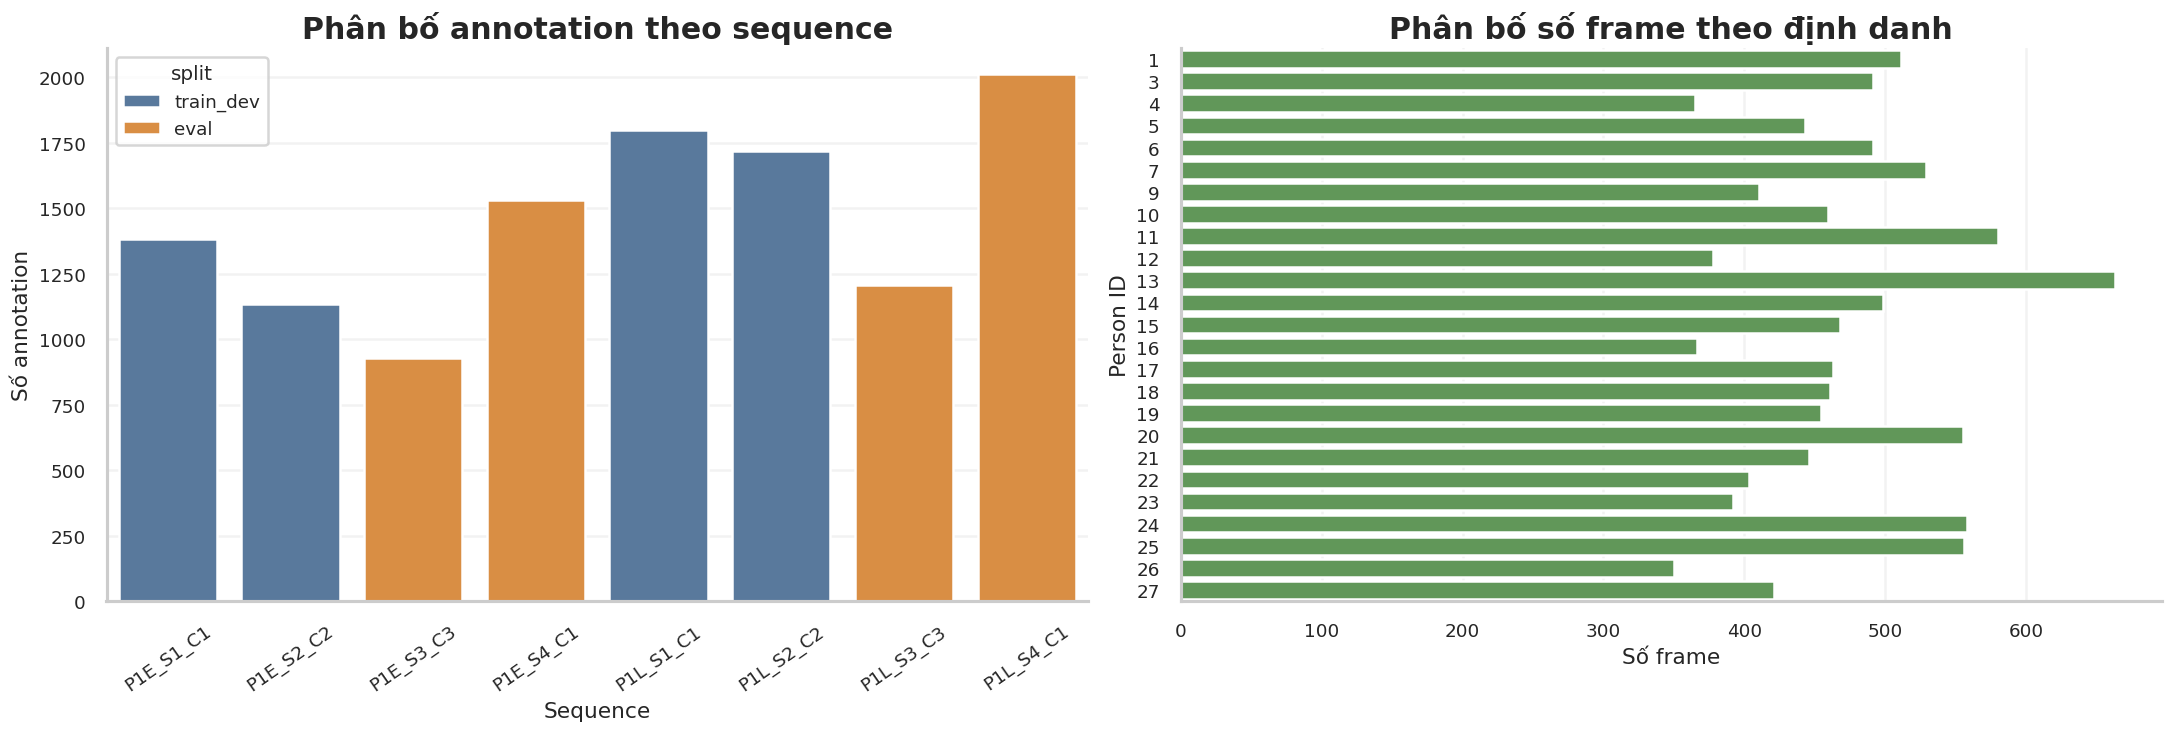

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)

seq_counts = manifest.groupby(["dataset", "split"]).size().reset_index(name="Số annotation")
sns.barplot(
    data=seq_counts,
    x="dataset",
    y="Số annotation",
    hue="split",
    palette={"train_dev": "#4E79A7", "eval": "#F28E2B"},
    ax=axes[0],
)
axes[0].set_title("Phân bố annotation theo sequence")
axes[0].set_xlabel("Sequence")
axes[0].set_ylabel("Số annotation")
axes[0].tick_params(axis="x", rotation=35)
style_axis(axes[0])

id_counts = manifest["person_id"].value_counts().sort_values(ascending=False).reset_index()
id_counts.columns = ["person_id", "Số frame"]
top_ids = id_counts.head(25)
sns.barplot(data=top_ids, y="person_id", x="Số frame", orient="h", color="#59A14F", ax=axes[1])
axes[1].set_title("Phân bố số frame theo định danh")
axes[1].set_xlabel("Số frame")
axes[1].set_ylabel("Person ID")
style_axis(axes[1], grid_axis="x")

save_figure(fig, "01_phan_bo_du_lieu")
plt.show()


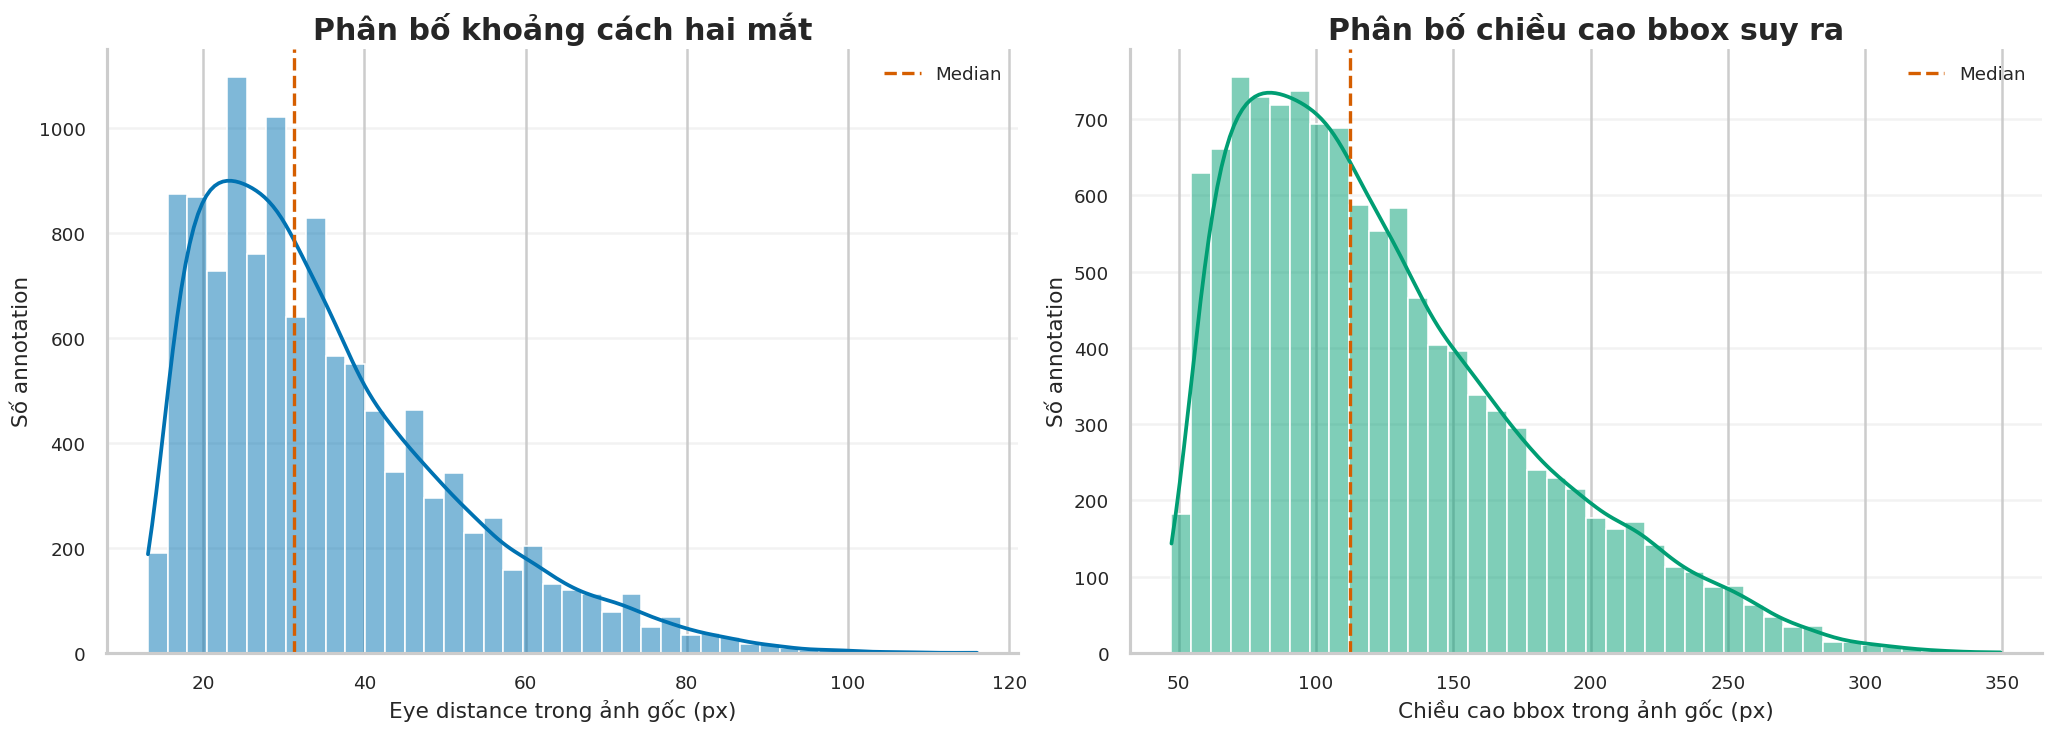

In [8]:
manifest = manifest.copy()
manifest["box_area"] = manifest["box_w"] * manifest["box_h"]

fig, axes = plt.subplots(1, 2, figsize=(17, 6), constrained_layout=True)

sns.histplot(manifest["eye_distance_px"], bins=42, kde=True, color="#0072B2", ax=axes[0])
axes[0].axvline(manifest["eye_distance_px"].median(), color="#D55E00", linestyle="--", linewidth=2, label="Median")
axes[0].set_title("Phân bố khoảng cách hai mắt")
axes[0].set_xlabel("Eye distance trong ảnh gốc (px)")
axes[0].set_ylabel("Số annotation")
axes[0].legend(frameon=False)
style_axis(axes[0])

sns.histplot(manifest["box_h"], bins=42, kde=True, color="#009E73", ax=axes[1])
axes[1].axvline(manifest["box_h"].median(), color="#D55E00", linestyle="--", linewidth=2, label="Median")
axes[1].set_title("Phân bố chiều cao bbox suy ra")
axes[1].set_xlabel("Chiều cao bbox trong ảnh gốc (px)")
axes[1].set_ylabel("Số annotation")
axes[1].legend(frameon=False)
style_axis(axes[1])

save_figure(fig, "02_phan_bo_kich_thuoc_mat")
plt.show()


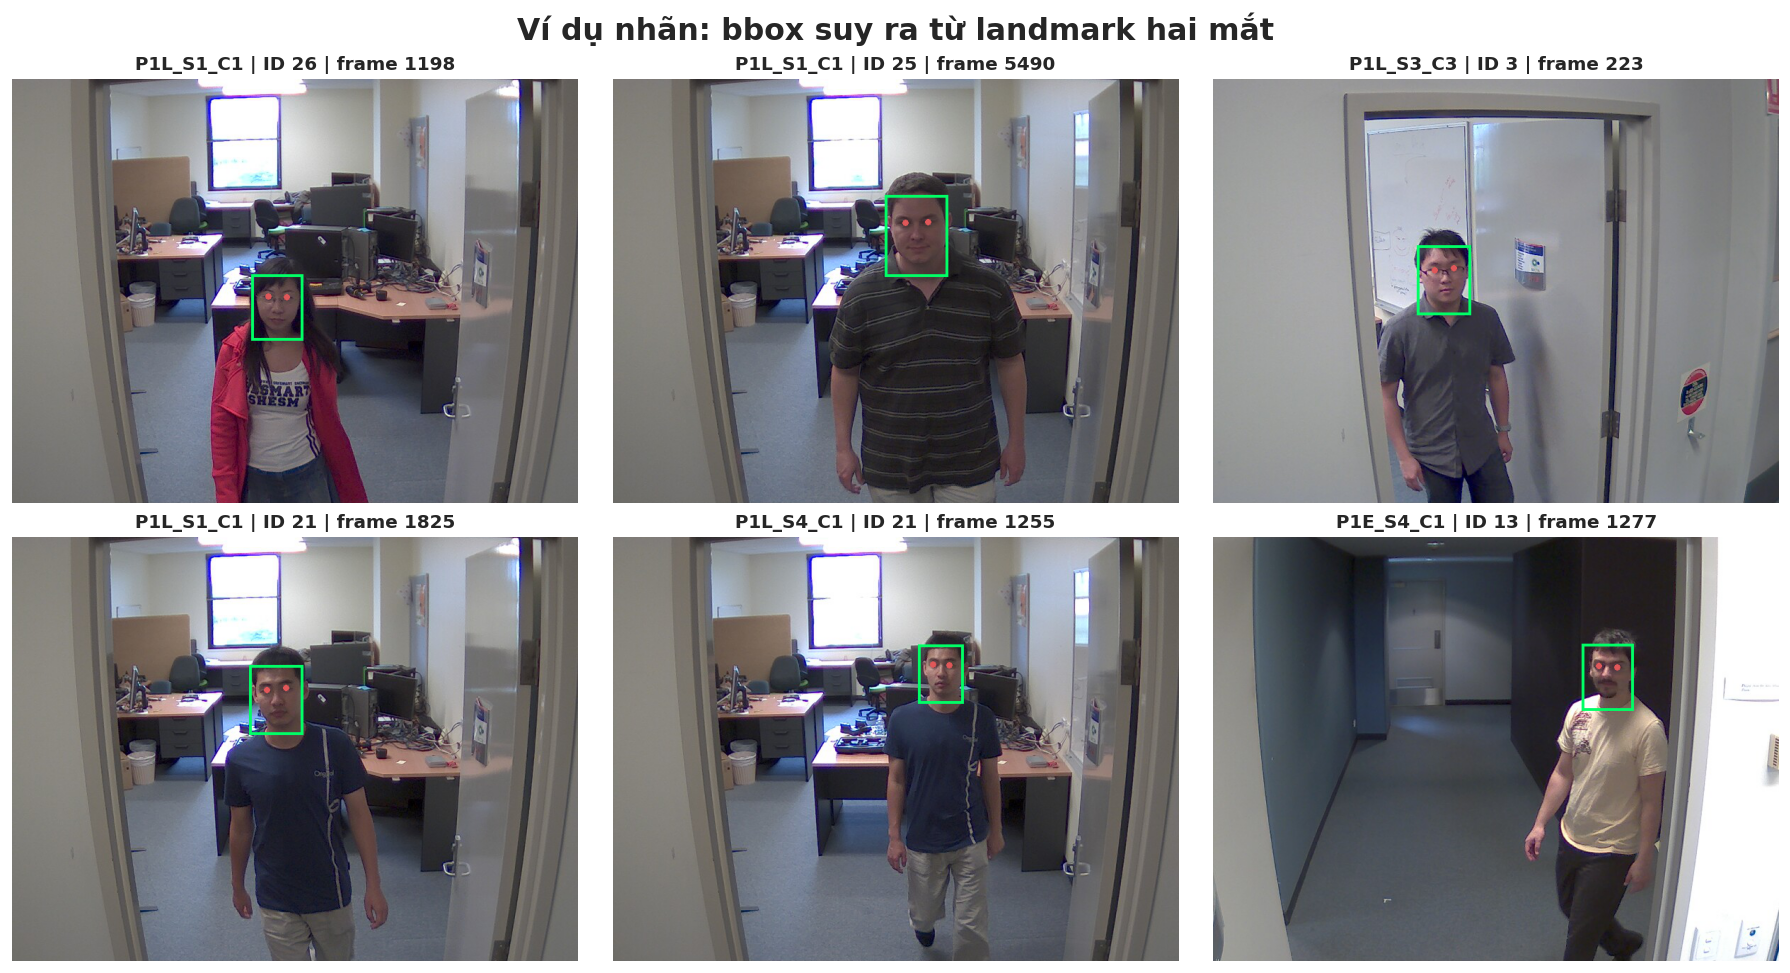

In [9]:
def draw_ground_truth_examples(rows: pd.DataFrame, title: str, max_images: int = 6) -> None:
    rendered = []
    skipped = 0
    for _, row in rows.iterrows():
        try:
            img = PILImage.open(row["image_path"]).convert("RGB")
        except (PermissionError, FileNotFoundError, OSError):
            skipped += 1
            continue
        draw = ImageDraw.Draw(img)
        draw.rectangle([row["x1"], row["y1"], row["x2"], row["y2"]], outline="#00FF66", width=4)
        draw.ellipse([row["left_eye_x"] - 4, row["left_eye_y"] - 4, row["left_eye_x"] + 4, row["left_eye_y"] + 4], fill="#E15759")
        draw.ellipse([row["right_eye_x"] - 4, row["right_eye_y"] - 4, row["right_eye_x"] + 4, row["right_eye_y"] + 4], fill="#E15759")
        rendered.append((img, row))
        if len(rendered) >= max_images:
            break
    if skipped:
        print(f"Bỏ qua {skipped} ảnh không đọc được trong môi trường hiện tại.")
    if not rendered:
        print("Không có ảnh đọc được để trực quan hóa trong môi trường hiện tại.")
        return
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
    axes = axes.ravel()
    for ax, (img, row) in zip(axes, rendered):
        ax.imshow(img)
        ax.set_title(f"{row['dataset']} | ID {row['person_id']} | frame {row['frame_number']}", fontsize=11)
        ax.axis("off")
    for ax in axes[len(rendered):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=18, fontweight="bold")
    save_figure(fig, "03_vi_du_nhan_bbox_tu_mat")
    plt.show()


example_rows = manifest.sample(min(600, len(manifest)), random_state=391)
draw_ground_truth_examples(example_rows, "Ví dụ nhãn: bbox suy ra từ landmark hai mắt")


## 7. Benchmark nền sau fine-tune ở độ phân giải gốc

Benchmark cố định sử dụng toàn bộ 5,676 frame trong eval split. Khác với phiên bản trước, YOLOv5n, YOLOv8n và YOLOv12n ở đây đã được fine-tune thành detector một lớp `face` trên bbox ChokePoint. Vì vậy bảng dưới là so sánh trực tiếp giữa YOLO face detector đã domain-adapted và SCRFD.


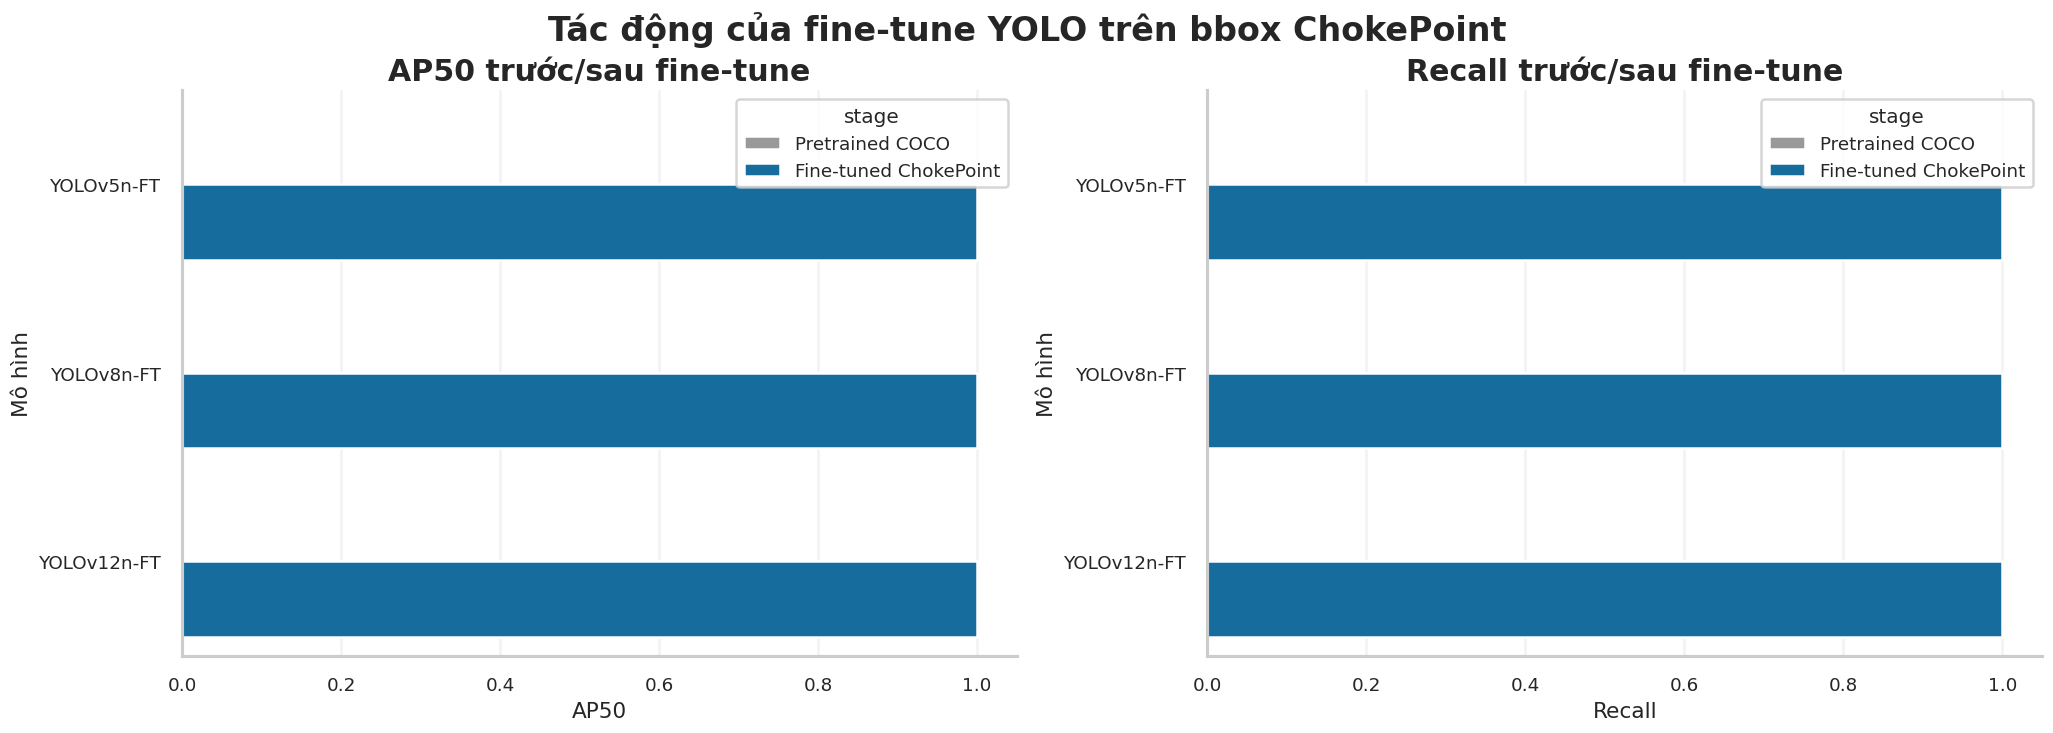

In [10]:
if not pretrained_benchmark.empty:
    pre_yolo = pretrained_benchmark[pretrained_benchmark["model"].str.startswith("YOLO")].copy()
    pre_yolo["family"] = pre_yolo["model"].str.replace("n", "n-FT", regex=False)
    ft_yolo = fixed_benchmark[fixed_benchmark["model"].str.startswith("YOLO")].copy()
    ft_yolo["family"] = ft_yolo["model"]
    before_after = pd.concat([
        pre_yolo.assign(stage="Pretrained COCO"),
        ft_yolo.assign(stage="Fine-tuned ChokePoint"),
    ], ignore_index=True)

    fig, axes = plt.subplots(1, 2, figsize=(17, 6), constrained_layout=True)
    for ax, metric, title in zip(axes, ["ap50_voc101", "recall"], ["AP50 trước/sau fine-tune", "Recall trước/sau fine-tune"]):
        sns.barplot(
            data=before_after,
            x=metric,
            y="family",
            hue="stage",
            palette={"Pretrained COCO": "#999999", "Fine-tuned ChokePoint": "#0072B2"},
            ax=ax,
        )
        ax.set_title(title)
        ax.set_xlabel(title.split()[0])
        ax.set_ylabel("Mô hình")
        ax.set_xlim(0, 1.05)
        style_axis(ax, grid_axis="x")
    fig.suptitle("Tác động của fine-tune YOLO trên bbox ChokePoint", fontsize=20, fontweight="bold")
    save_figure(fig, "04_yolo_before_after_finetune")
    plt.show()


In [11]:
fixed_cols = [
    "model", "device", "sample_size", "predictions_raw", "tp", "fp", "fn",
    "precision", "recall", "f1", "ap50_voc101", "mean_matched_iou", "ms_per_image", "fps", "weights",
]
fixed_cols = [col for col in fixed_cols if col in fixed_benchmark.columns]
fixed_display = (
    fixed_benchmark[fixed_cols]
    .sort_values("ap50_voc101", ascending=False)
    .round({
        "precision": 4, "recall": 4, "f1": 4, "ap50_voc101": 4,
        "mean_matched_iou": 4, "ms_per_image": 2, "fps": 2,
    })
)
display(fixed_display)


,model,device,sample_size,predictions_raw,tp,fp,fn,precision,recall,f1,ap50_voc101,mean_matched_iou,ms_per_image,fps,weights
3,YOLOv5n-FT,0,5676,6259,5676,2,0,0.9996,1.0000,0.9998,1.0000,0.9283,14.02,71.34,chokepoint_data\modeling\yolo_finetuned_full_g...
4,YOLOv8n-FT,0,5676,6435,5676,0,0,1.0000,1.0000,1.0000,1.0000,0.9261,13.22,75.65,chokepoint_data\modeling\yolo_finetuned_full_g...
5,YOLOv12n-FT,0,5676,6499,5676,0,0,1.0000,1.0000,1.0000,1.0000,0.9255,18.59,53.79,chokepoint_data\modeling\yolo_finetuned_full_g...
6,SCRFD,ctx_id=0,5676,5696,5657,39,19,0.9932,0.9967,0.9949,0.9879,0.6204,22.43,44.58,InsightFace buffalo_l / det_10g.onnx


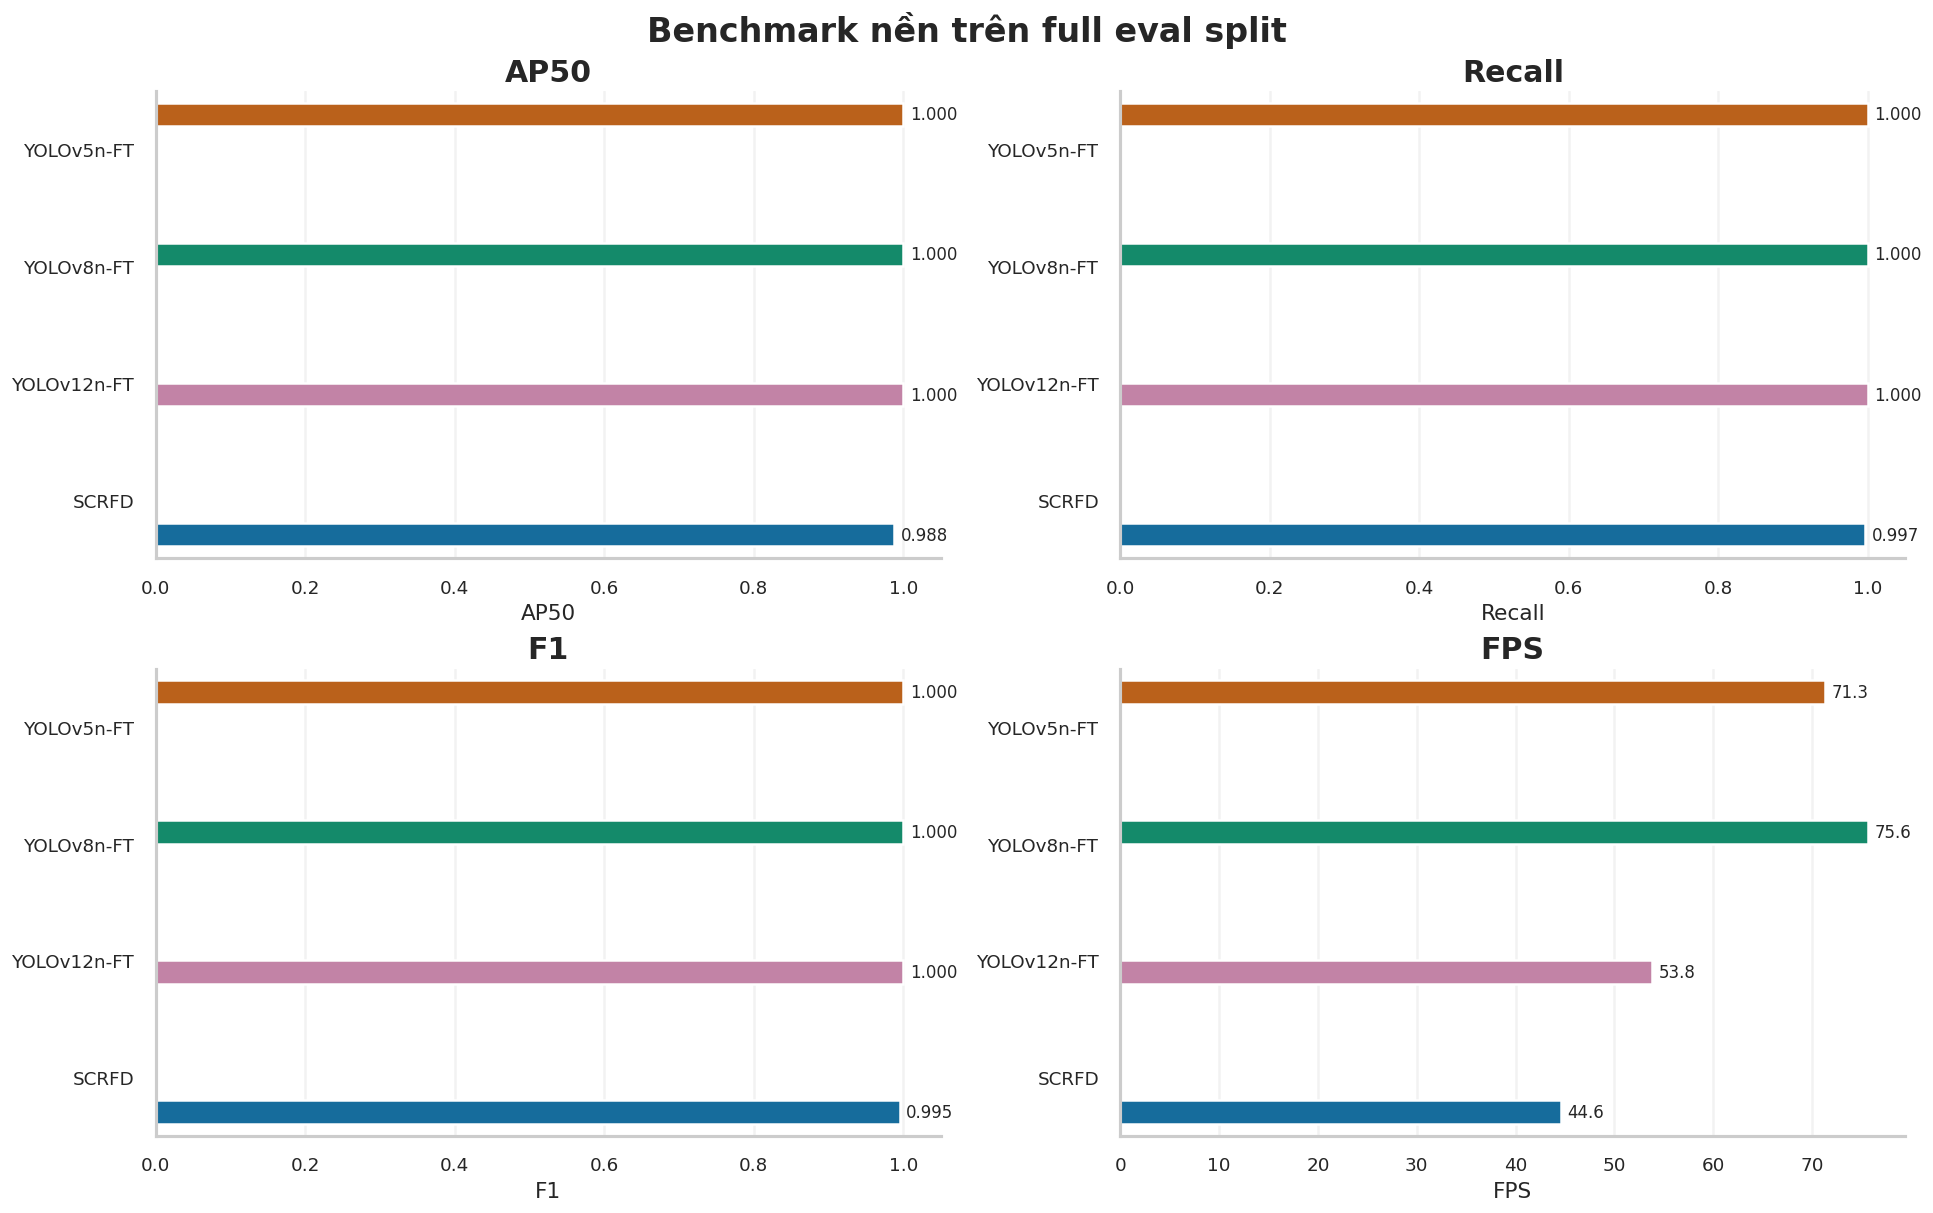

In [12]:
baseline_long = fixed_benchmark.melt(
    id_vars=["model"],
    value_vars=["ap50_voc101", "recall", "f1", "fps"],
    var_name="Metric",
    value_name="Value",
)
metric_labels = {
    "ap50_voc101": "AP50",
    "recall": "Recall",
    "f1": "F1",
    "fps": "FPS",
}
baseline_long["Metric"] = baseline_long["Metric"].map(metric_labels)
baseline_long["model"] = pd.Categorical(baseline_long["model"], MODEL_ORDER, ordered=True)

fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)
for ax, metric in zip(axes.ravel(), ["AP50", "Recall", "F1", "FPS"]):
    data = baseline_long[baseline_long["Metric"] == metric].sort_values("model")
    sns.barplot(
        data=data,
        x="Value",
        y="model",
        hue="model",
        palette=MODEL_COLORS,
        legend=False,
        ax=ax,
    )
    ax.set_title(metric)
    ax.set_xlabel(metric)
    ax.set_ylabel("")
    if metric != "FPS":
        ax.set_xlim(0, 1.05)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f" if metric != "FPS" else "%.1f", padding=4, fontsize=10)
    style_axis(ax, grid_axis="x")

fig.suptitle("Benchmark nền trên full eval split", fontsize=20, fontweight="bold")
save_figure(fig, "05_benchmark_nen_full_eval")
plt.show()


## 8. Đường cong độ phân giải

Ở mỗi mức độ phân giải, ảnh `800x600` được resize xuống trước khi inference. Bbox dự đoán sau đó được scale ngược về hệ tọa độ ảnh gốc để tính IoU với bbox suy ra từ landmark. Cách này giữ nguyên cùng một tập nhãn cho mọi mức resolution.

Đường cong chính dùng confidence threshold `0.25`. Phần threshold được phân tích riêng ở mục 9.


In [13]:
resolution_cols = [
    "model", "device", "resolution_label", "resolution_width", "conf_threshold", "sample_size",
    "predictions_raw", "predictions_at_threshold", "tp", "fp", "fn",
    "precision", "recall", "f1", "ap50_voc101", "mean_matched_iou", "ms_per_image", "fps",
]
resolution_cols = [col for col in resolution_cols if col in primary_res.columns]
resolution_display = (
    primary_res[resolution_cols]
    .sort_values(["model", "resolution_width"], ascending=[True, False])
    .round({
        "precision": 4, "recall": 4, "f1": 4, "ap50_voc101": 4,
        "mean_matched_iou": 4, "ms_per_image": 2, "fps": 2,
    })
)
display(resolution_display)


,model,device,resolution_label,resolution_width,conf_threshold,sample_size,predictions_raw,predictions_at_threshold,tp,fp,fn,precision,recall,f1,ap50_voc101,mean_matched_iou,ms_per_image,fps
18,SCRFD,ctx_id=0,480p (640x480),640,0.25,5676,5700,5700,5656,44,20,0.9923,0.9965,0.9944,0.9878,0.6204,23.62,42.34
42,SCRFD,ctx_id=0,360p (480x360),480,0.25,5676,5677,5677,5651,26,25,0.9954,0.9956,0.9955,0.9875,0.6208,16.13,61.98
66,SCRFD,ctx_id=0,288p (384x288),384,0.25,5676,5681,5681,5621,60,55,0.9894,0.9903,0.9899,0.9863,0.6180,14.23,70.29
90,SCRFD,ctx_id=0,240p (320x240),320,0.25,5676,5686,5686,5555,131,121,0.9770,0.9787,0.9778,0.9637,0.6147,12.44,80.36
114,SCRFD,ctx_id=0,216p (288x216),288,0.25,5676,5677,5677,5553,124,123,0.9782,0.9783,0.9782,0.9651,0.6121,13.09,76.41
138,SCRFD,ctx_id=0,192p (256x192),256,0.25,5676,5691,5691,5483,208,193,0.9635,0.9660,0.9647,0.9541,0.6095,12.46,80.24
162,SCRFD,ctx_id=0,180p (240x180),240,0.25,5676,5698,5698,5427,271,249,0.9524,0.9561,0.9543,0.9432,0.6080,11.92,83.88
186,SCRFD,ctx_id=0,144p (192x144),192,0.25,5676,5688,5688,5379,309,297,0.9457,0.9477,0.9467,0.9313,0.6078,15.48,64.61
210,SCRFD,ctx_id=0,120p (160x120),160,0.25,5676,5686,5686,5334,352,342,0.9381,0.9397,0.9389,0.9192,0.6064,14.60,68.50
234,SCRFD,ctx_id=0,96p (128x96),128,0.25,5676,5616,5616,5197,419,479,0.9254,0.9156,0.9205,0.8915,0.6100,16.54,60.47


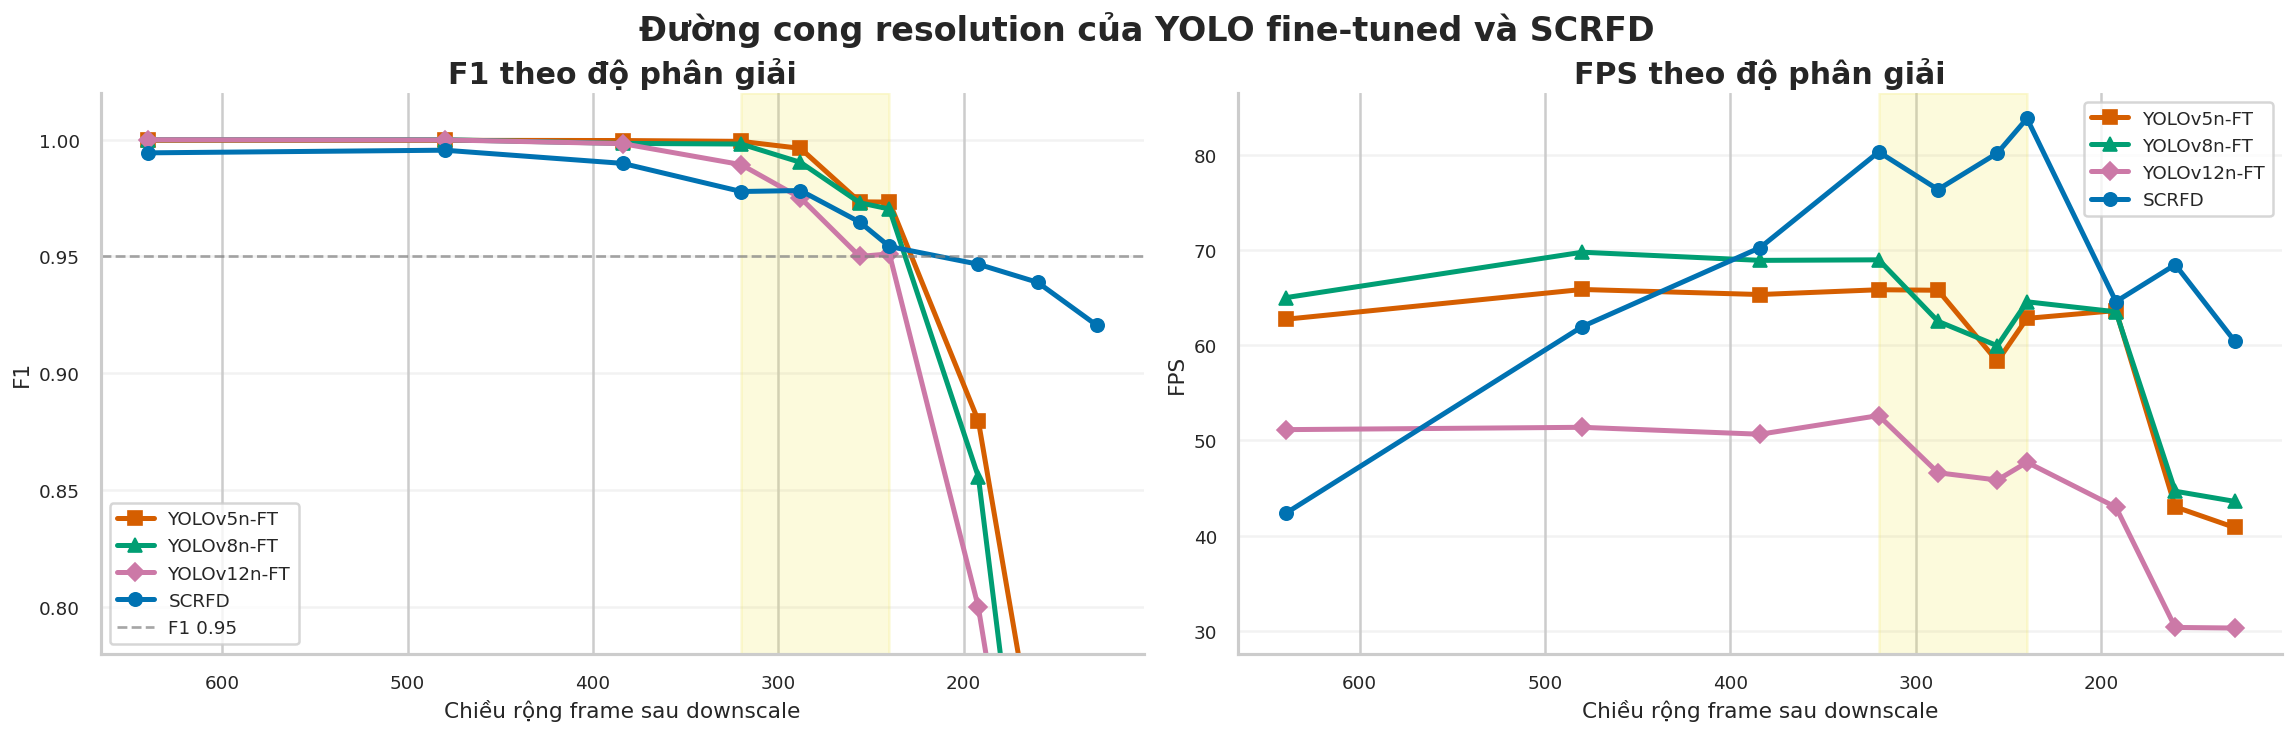

In [14]:
model_curves = primary_res.copy()
model_curves["acceptable"] = (model_curves["ap50_voc101"] >= 0.95) & (model_curves["recall"] >= 0.97)
model_curves["speedup_vs_640"] = np.nan
for model in model_curves["model"].unique():
    base = model_curves[(model_curves["model"] == model) & (model_curves["resolution_width"] == 640)]["fps"]
    if len(base):
        model_curves.loc[model_curves["model"] == model, "speedup_vs_640"] = model_curves.loc[model_curves["model"] == model, "fps"] / float(base.iloc[0])

fig, axes = plt.subplots(1, 2, figsize=(19, 6), constrained_layout=True)

for model in MODEL_ORDER:
    group = model_curves[model_curves["model"] == model].sort_values("resolution_width", ascending=False)
    if group.empty:
        continue
    axes[0].plot(
        group["resolution_width"], group["f1"],
        color=MODEL_COLORS[model],
        marker=MODEL_MARKERS[model],
        linewidth=3,
        markersize=8,
        label=model,
    )
    axes[1].plot(
        group["resolution_width"], group["fps"],
        color=MODEL_COLORS[model],
        marker=MODEL_MARKERS[model],
        linewidth=3,
        markersize=8,
        label=model,
    )

for ax in axes:
    ax.axvspan(240, 320, color="#F0E442", alpha=0.18)
    ax.invert_xaxis()
    style_axis(ax)

axes[0].axhline(0.95, color="gray", linestyle="--", linewidth=1.6, alpha=0.7, label="F1 0.95")
axes[0].set_title("F1 theo độ phân giải")
axes[0].set_xlabel("Chiều rộng frame sau downscale")
axes[0].set_ylabel("F1")
axes[0].set_ylim(0.78, 1.02)
axes[0].legend(frameon=True, loc="lower left")

axes[1].set_title("FPS theo độ phân giải")
axes[1].set_xlabel("Chiều rộng frame sau downscale")
axes[1].set_ylabel("FPS")
axes[1].legend(frameon=True, loc="upper right")

fig.suptitle("Đường cong resolution của YOLO fine-tuned và SCRFD", fontsize=20, fontweight="bold")
save_figure(fig, "06_detector_resolution_curves")
plt.show()


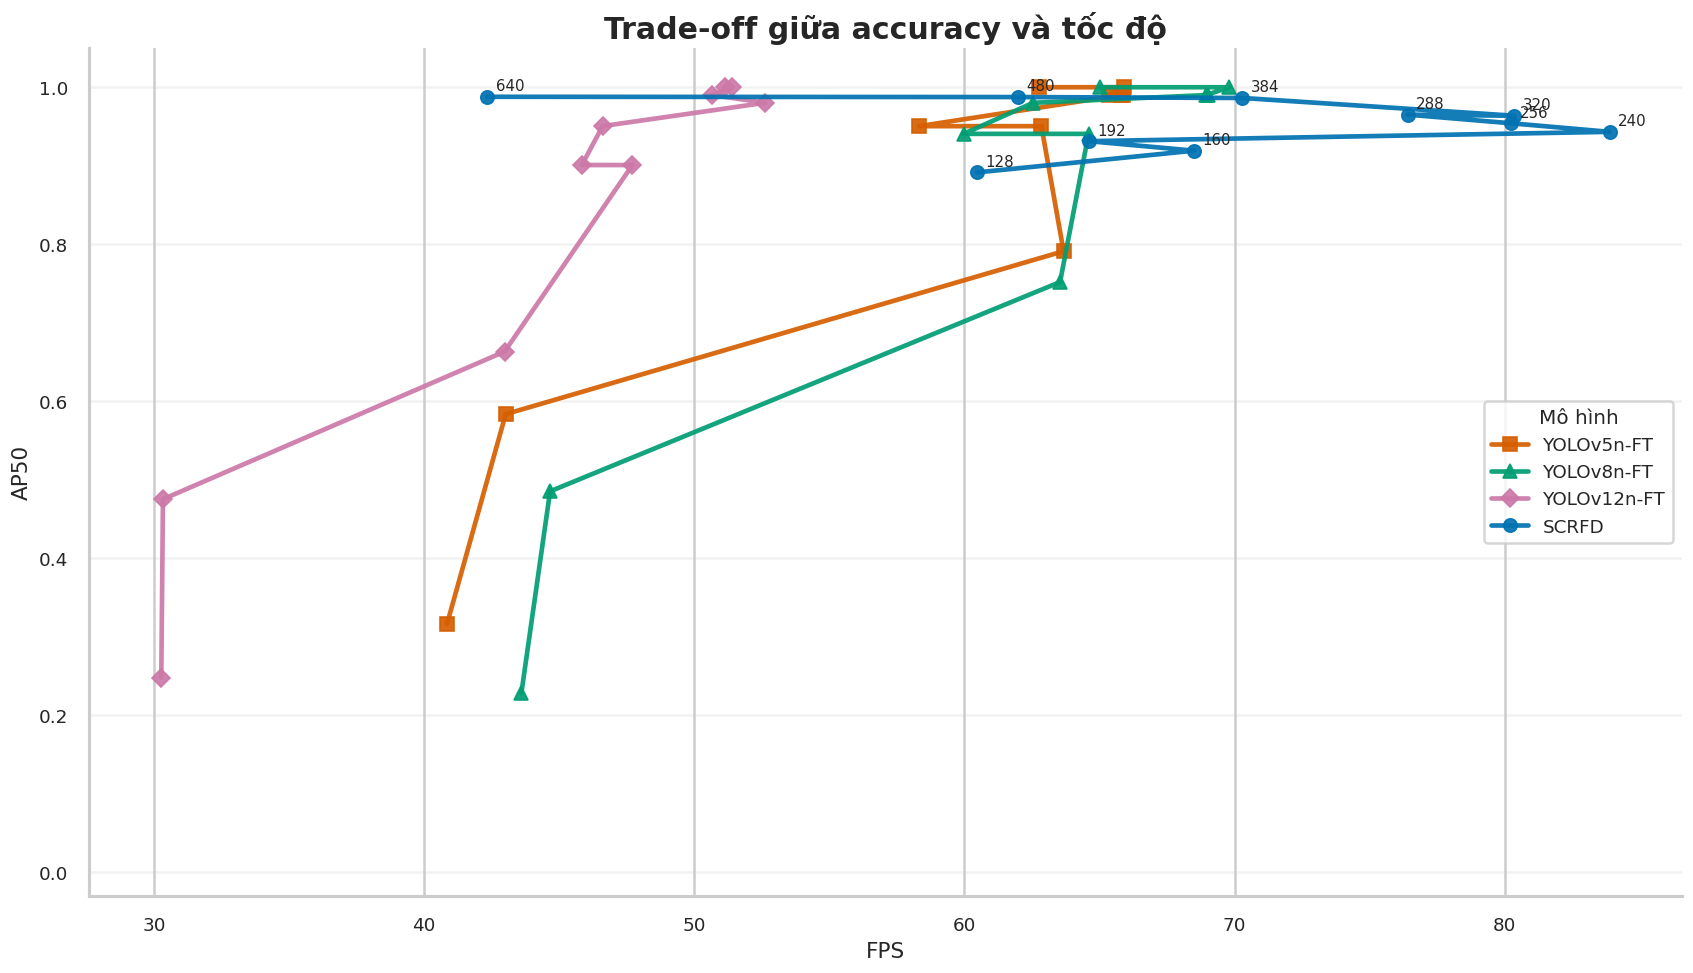

In [15]:
fig, ax = plt.subplots(figsize=(14, 8), constrained_layout=True)

for model in MODEL_ORDER:
    group = primary_res[primary_res["model"] == model].sort_values("resolution_width")
    if group.empty:
        continue
    ax.plot(
        group["fps"], group["ap50_voc101"],
        label=model,
        color=MODEL_COLORS[model],
        marker=MODEL_MARKERS[model],
        linewidth=2.8,
        markersize=8,
        alpha=0.92,
    )

scrfd_points = primary_res[primary_res["model"] == "SCRFD"]
for _, row in scrfd_points.iterrows():
    ax.annotate(str(int(row["resolution_width"])), (row["fps"], row["ap50_voc101"]), xytext=(5, 4), textcoords="offset points", fontsize=9)

ax.set_title("Trade-off giữa accuracy và tốc độ")
ax.set_xlabel("FPS")
ax.set_ylabel("AP50")
ax.set_ylim(-0.03, 1.05)
ax.legend(title="Mô hình", frameon=True, loc="center right")
style_axis(ax)
save_figure(fig, "07_tradeoff_accuracy_speed")
plt.show()


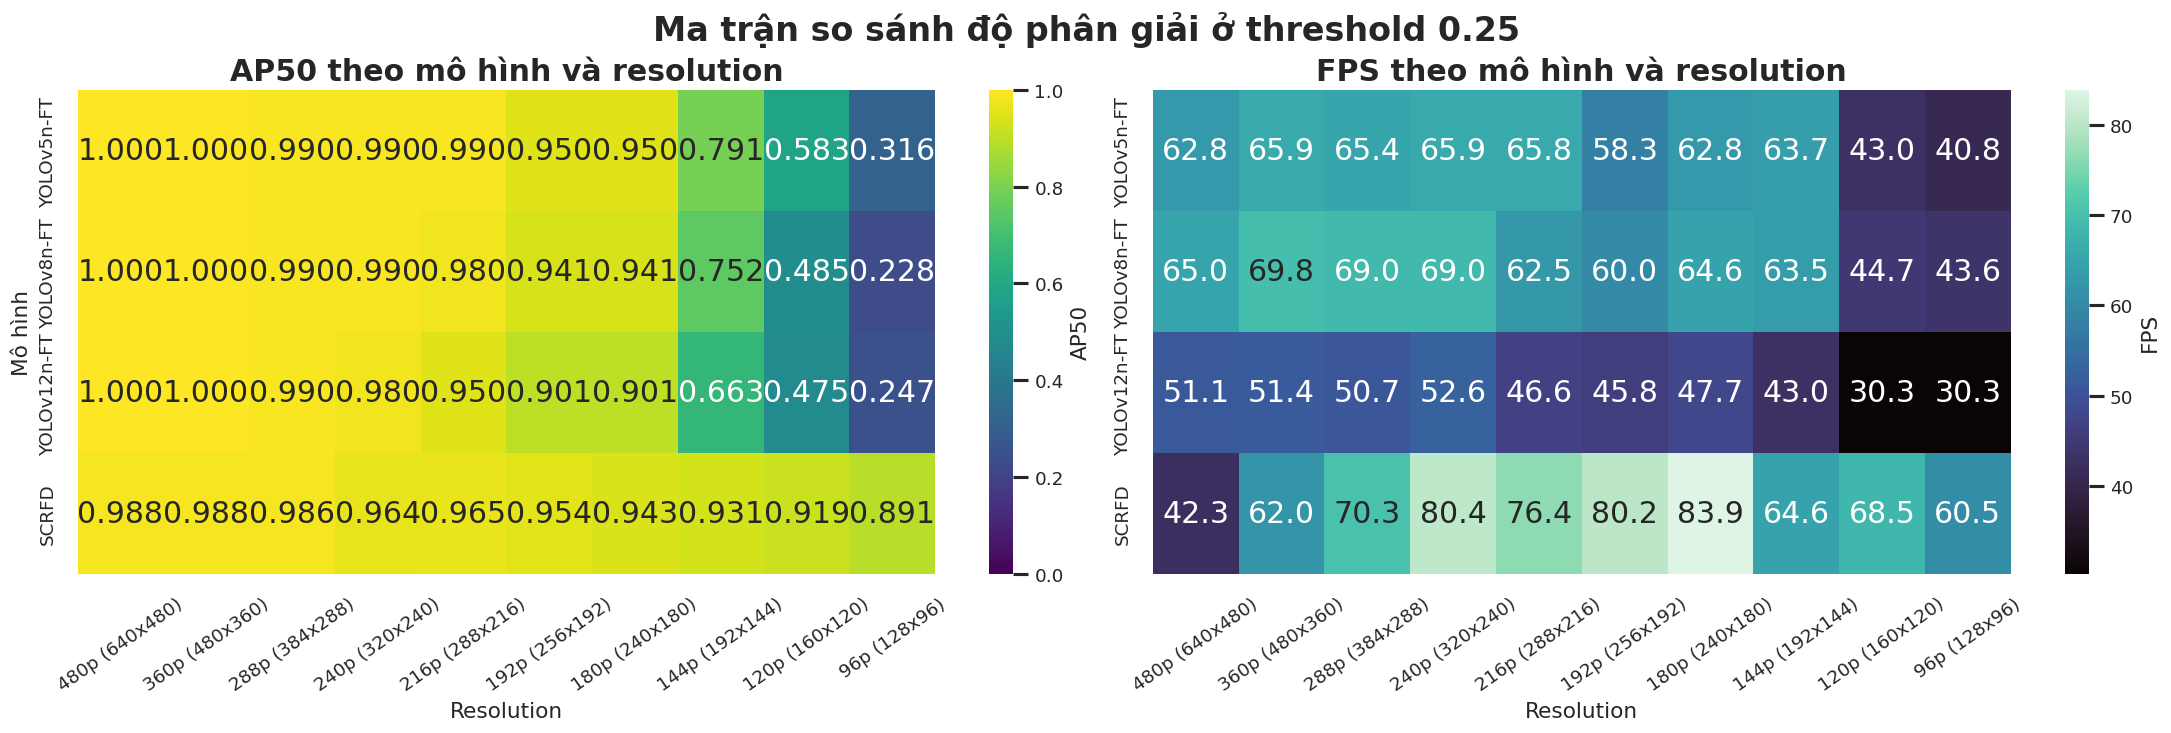

In [16]:
ordered_labels = (
    primary_res[["resolution_width", "resolution_label"]]
    .drop_duplicates()
    .sort_values("resolution_width", ascending=False)["resolution_label"]
    .tolist()
)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)

ap_pivot = (
    primary_res.pivot(index="model", columns="resolution_label", values="ap50_voc101")
    .reindex(index=MODEL_ORDER, columns=ordered_labels)
)
fps_pivot = (
    primary_res.pivot(index="model", columns="resolution_label", values="fps")
    .reindex(index=MODEL_ORDER, columns=ordered_labels)
)

sns.heatmap(ap_pivot, annot=True, fmt=".3f", cmap="viridis", vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "AP50"})
axes[0].set_title("AP50 theo mô hình và resolution")
axes[0].set_xlabel("Resolution")
axes[0].set_ylabel("Mô hình")
axes[0].tick_params(axis="x", rotation=35)

sns.heatmap(fps_pivot, annot=True, fmt=".1f", cmap="mako", ax=axes[1], cbar_kws={"label": "FPS"})
axes[1].set_title("FPS theo mô hình và resolution")
axes[1].set_xlabel("Resolution")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=35)

fig.suptitle("Ma trận so sánh độ phân giải ở threshold 0.25", fontsize=20, fontweight="bold")
save_figure(fig, "08_heatmap_model_resolution")
plt.show()


## 9. Phân tích confidence threshold

Threshold là tham số vận hành quan trọng. Khi tăng threshold, hệ thống thường giảm false positive nhưng đồng thời tăng false negative. Hiệu ứng này mạnh hơn ở ảnh low-resolution vì confidence của detector kém ổn định hơn.

AP50 không phải metric tốt để vẽ theo threshold vì AP50 đã được tính từ danh sách prediction sắp xếp theo confidence. Do đó phần này tập trung vào Precision, Recall, F1, FP, FN và số detection được chấp nhận.


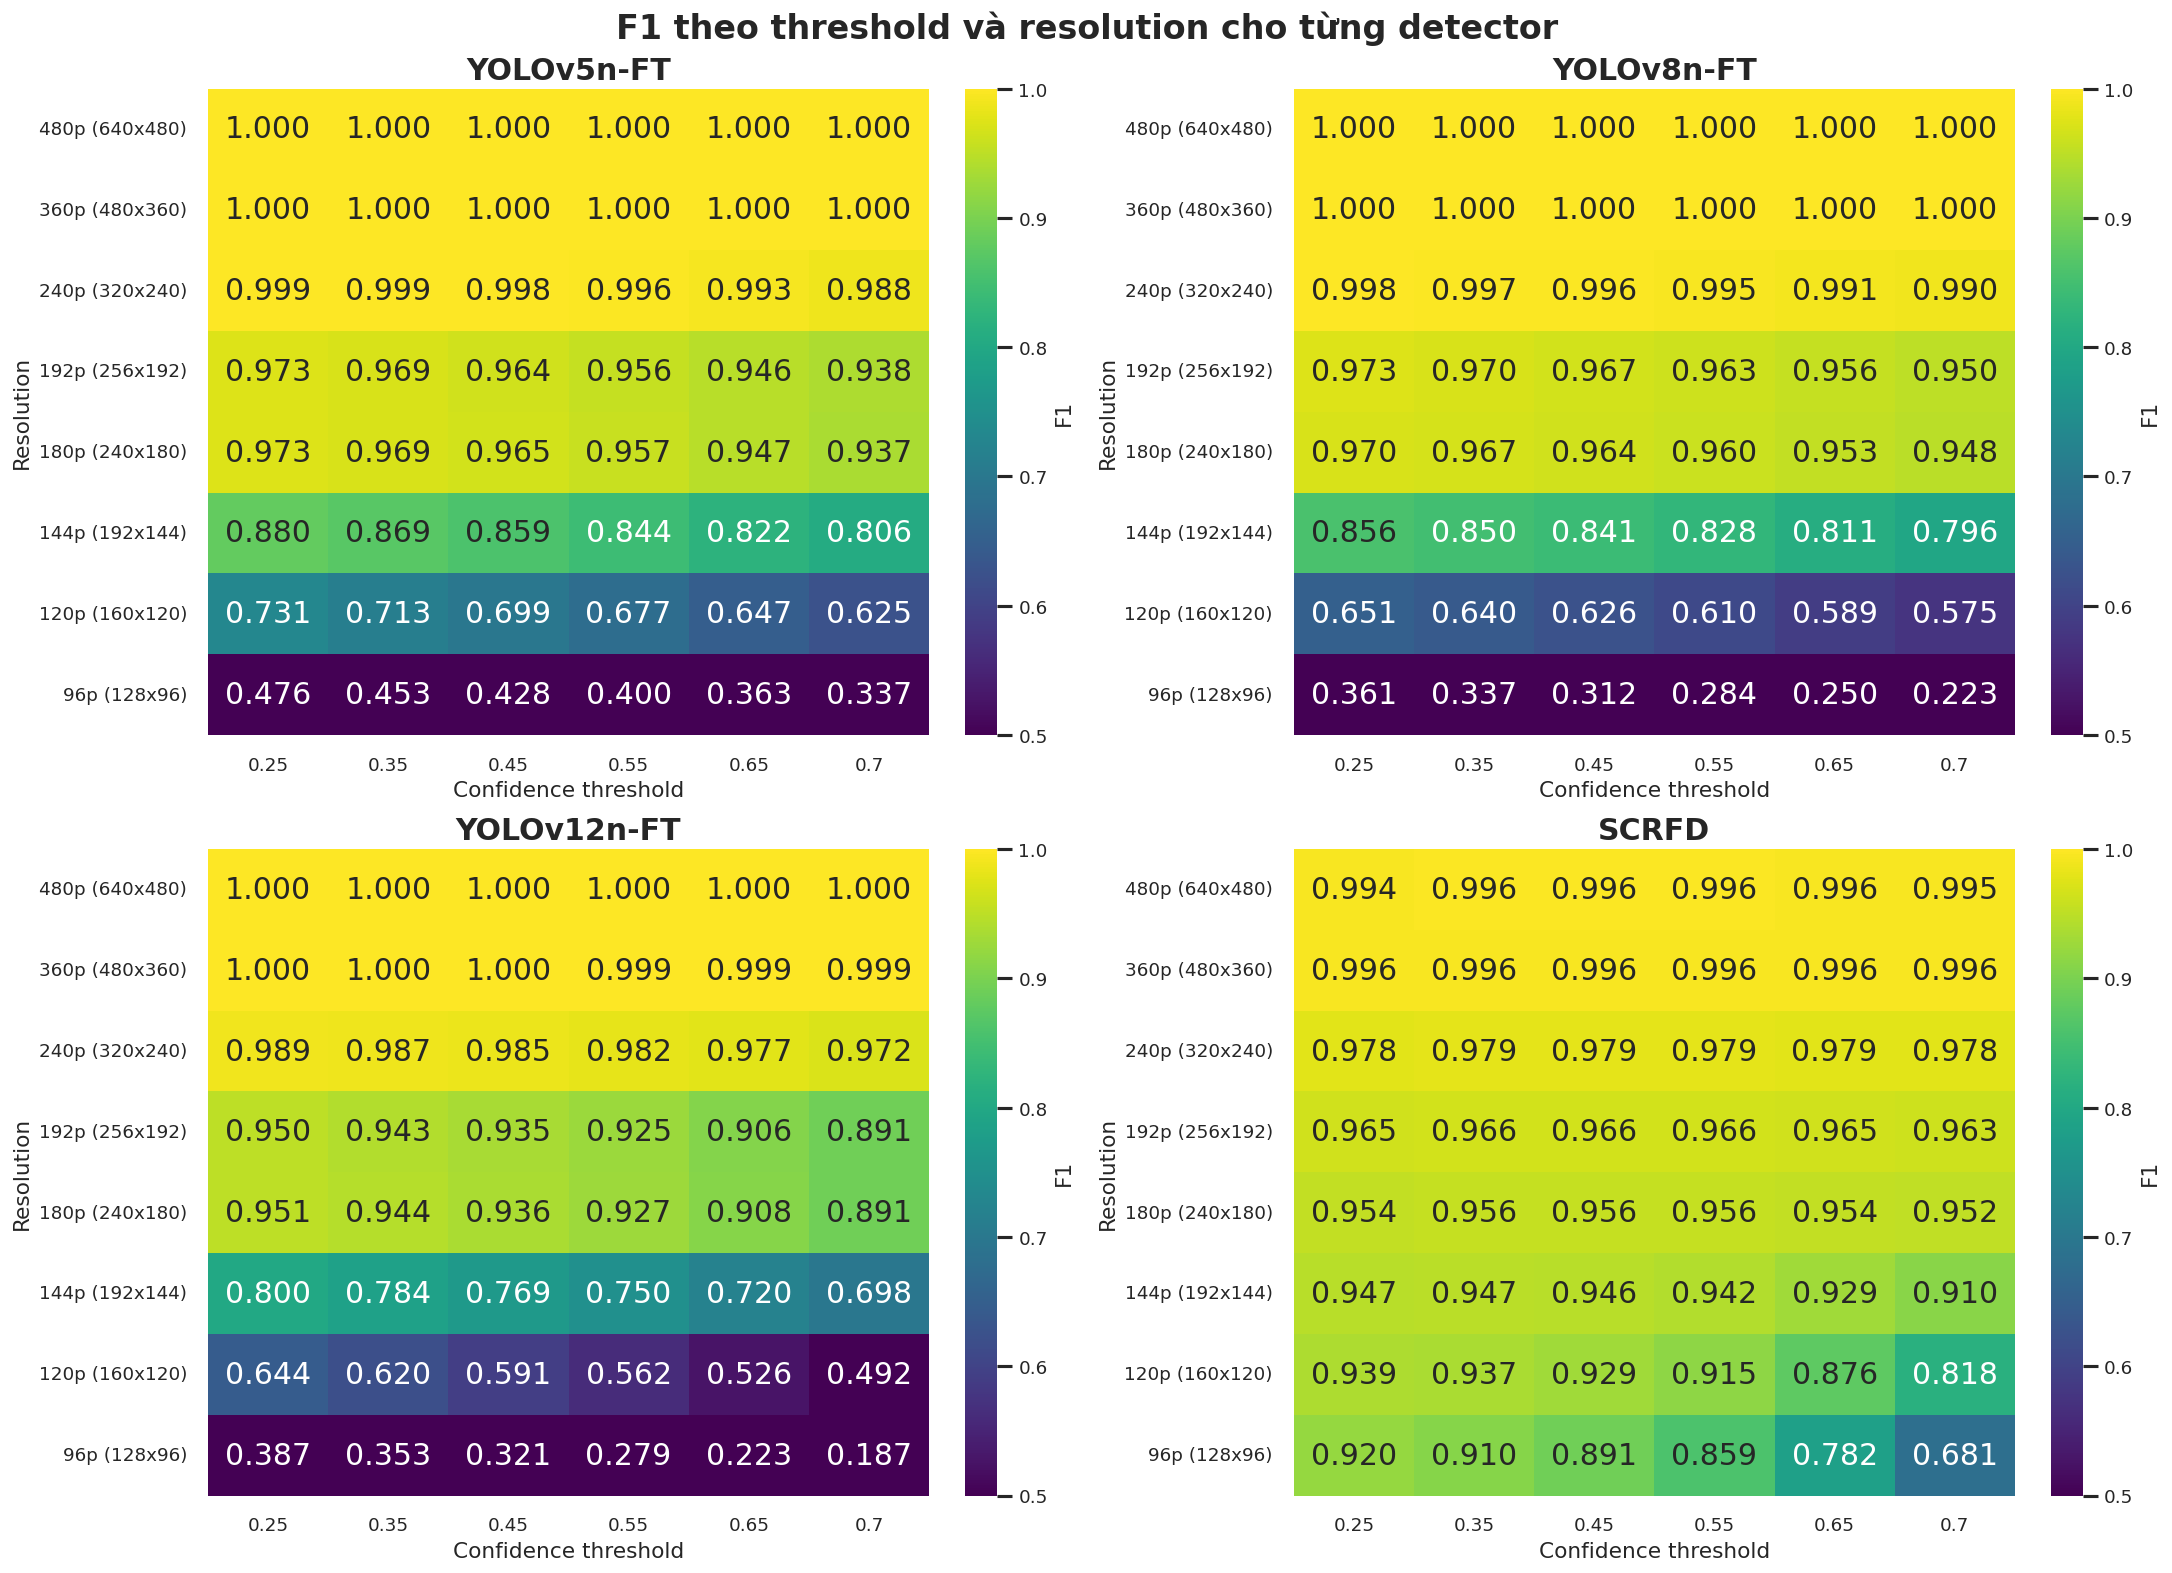

In [17]:
selected_widths = [640, 480, 320, 256, 240, 192, 160, 128]
threshold_data = resolution_benchmark[resolution_benchmark["resolution_width"].isin(selected_widths)].copy()
threshold_labels = (
    threshold_data[["resolution_width", "resolution_label"]]
    .drop_duplicates()
    .sort_values("resolution_width", ascending=False)["resolution_label"]
    .tolist()
)

fig, axes = plt.subplots(2, 2, figsize=(18, 13), constrained_layout=True)

for ax, model in zip(axes.ravel(), MODEL_ORDER):
    model_threshold = threshold_data[threshold_data["model"] == model]
    f1_heatmap = (
        model_threshold.pivot(index="resolution_label", columns="conf_threshold", values="f1")
        .reindex(index=threshold_labels)
    )
    sns.heatmap(f1_heatmap, annot=True, fmt=".3f", cmap="viridis", vmin=0.50, vmax=1.0, ax=ax, cbar_kws={"label": "F1"})
    ax.set_title(model)
    ax.set_xlabel("Confidence threshold")
    ax.set_ylabel("Resolution")

fig.suptitle("F1 theo threshold và resolution cho từng detector", fontsize=20, fontweight="bold")
save_figure(fig, "09_heatmap_threshold_all_detectors")
plt.show()


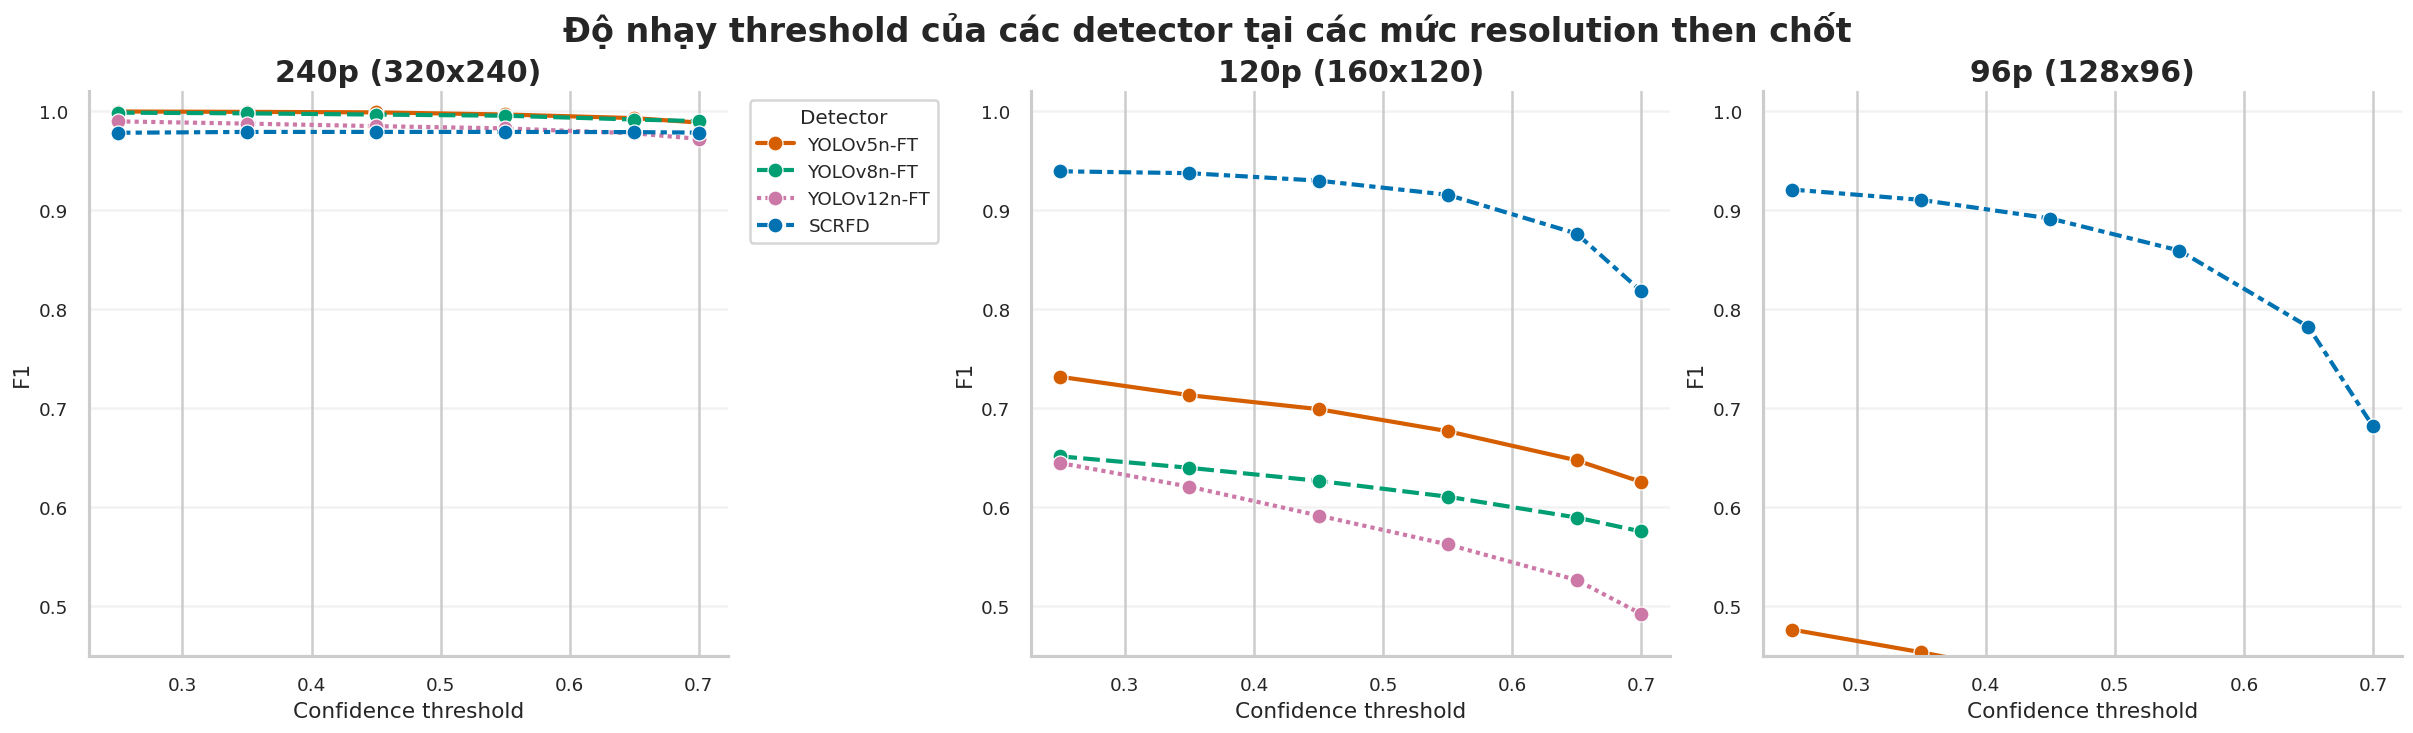

In [18]:
plot_threshold = threshold_data[threshold_data["resolution_width"].isin([320, 160, 128])].copy()
all_resolution_labels = (
    threshold_data[["resolution_width", "resolution_label"]]
    .drop_duplicates()
    .sort_values("resolution_width", ascending=False)["resolution_label"]
    .tolist()
)
palette_by_resolution = dict(zip(
    all_resolution_labels,
    sns.color_palette("colorblind", n_colors=len(all_resolution_labels)),
))

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, constrained_layout=True)

for ax, width in zip(axes, [320, 160, 128]):
    data = plot_threshold[plot_threshold["resolution_width"] == width]
    sns.lineplot(
        data=data,
        x="conf_threshold",
        y="f1",
        hue="model",
        style="model",
        marker="o",
        linewidth=2.5,
        palette=MODEL_COLORS,
        ax=ax,
    )
    label = data["resolution_label"].iloc[0] if len(data) else f"{width}px"
    ax.set_title(label)
    ax.set_xlabel("Confidence threshold")
    ax.set_ylabel("F1")
    ax.set_ylim(0.45, 1.02)
    style_axis(ax)

axes[0].legend(title="Detector", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
axes[1].legend_.remove()
axes[2].legend_.remove()
fig.suptitle("Độ nhạy threshold của các detector tại các mức resolution then chốt", fontsize=20, fontweight="bold")
save_figure(fig, "10_threshold_precision_recall_f1")
plt.show()


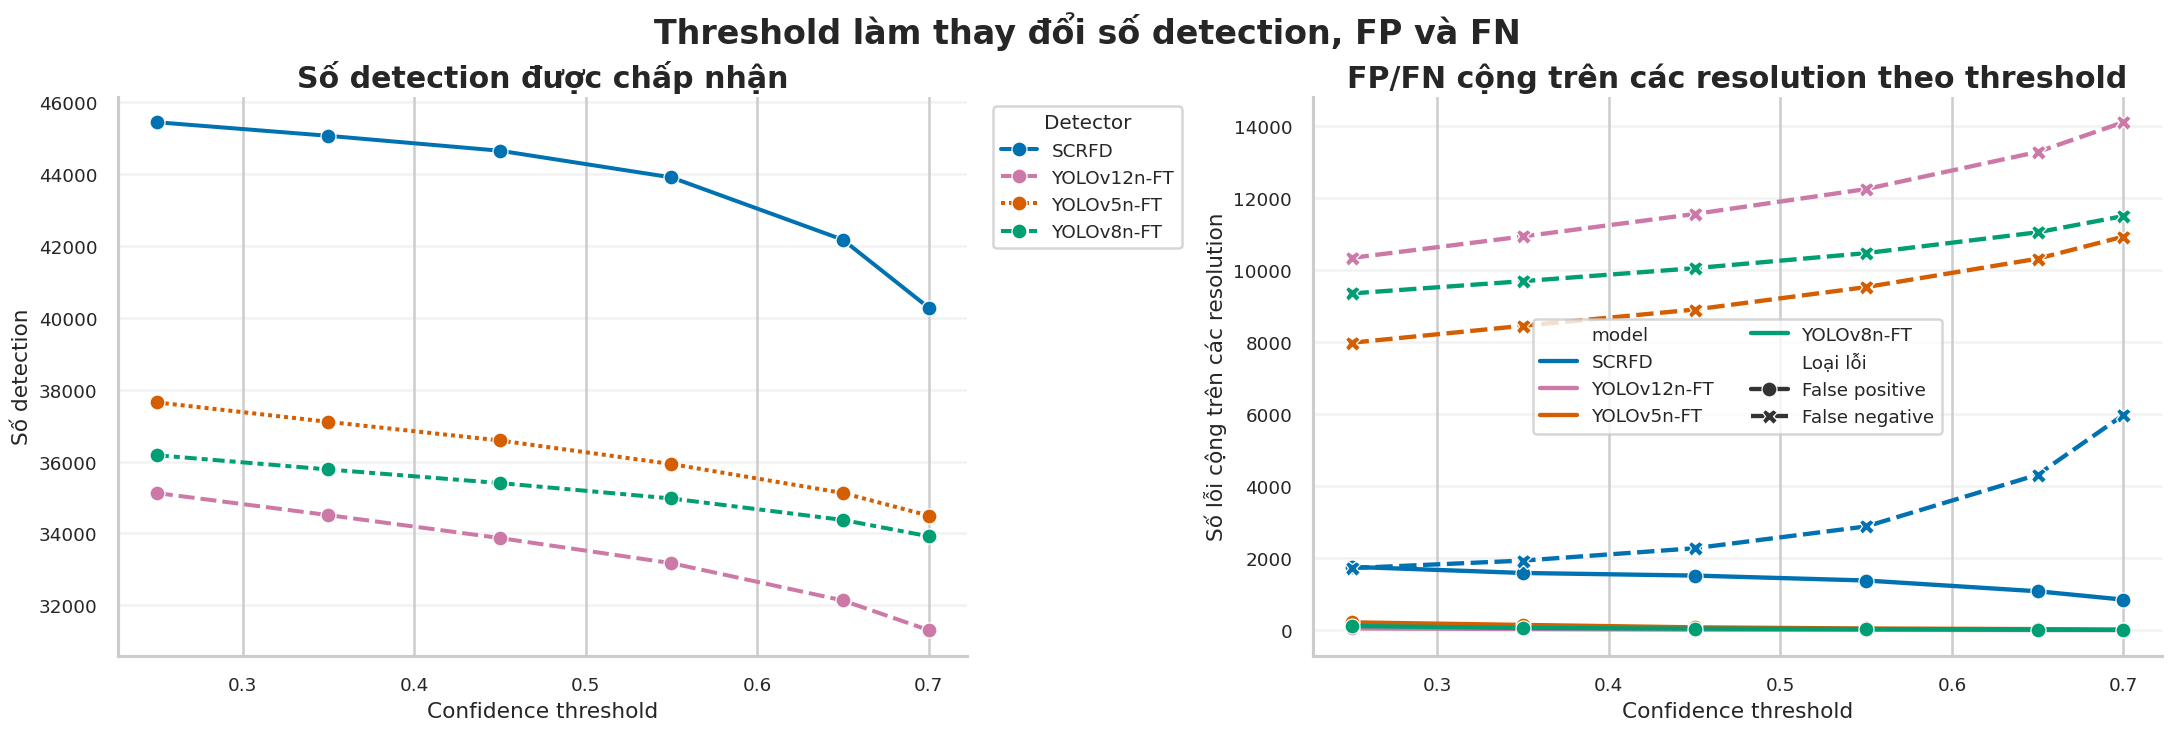

,model,resolution_label,conf_threshold,precision,recall,f1,fp,fn
20,SCRFD,480p (640x480),0.45,0.9965,0.9965,0.9965,20,20
45,SCRFD,360p (480x360),0.55,0.9956,0.9956,0.9956,25,25
67,SCRFD,288p (384x288),0.35,0.9903,0.9903,0.9903,55,55
91,SCRFD,240p (320x240),0.35,0.9787,0.9787,0.9787,121,121
115,SCRFD,216p (288x216),0.35,0.9783,0.9783,0.9783,123,123
139,SCRFD,192p (256x192),0.35,0.9660,0.9660,0.9660,193,193
165,SCRFD,180p (240x180),0.55,0.9571,0.9551,0.9561,243,255
187,SCRFD,144p (192x144),0.35,0.9478,0.9471,0.9475,296,300
210,SCRFD,120p (160x120),0.25,0.9381,0.9397,0.9389,352,342
234,SCRFD,96p (128x96),0.25,0.9254,0.9156,0.9205,419,479


In [19]:
error_by_model = threshold_data.groupby(["model", "conf_threshold"], as_index=False).agg(
    fp=("fp", "sum"),
    fn=("fn", "sum"),
    predictions_at_threshold=("predictions_at_threshold", "sum"),
)
error_melt = error_by_model.melt(
    id_vars=["model", "conf_threshold"],
    value_vars=["fp", "fn"],
    var_name="Loại lỗi",
    value_name="Số lượng",
)
error_melt["Loại lỗi"] = error_melt["Loại lỗi"].map({"fp": "False positive", "fn": "False negative"})

fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)

sns.lineplot(
    data=error_by_model,
    x="conf_threshold",
    y="predictions_at_threshold",
    hue="model",
    style="model",
    marker="o",
    linewidth=2.4,
    palette=MODEL_COLORS,
    ax=axes[0],
)
axes[0].set_title("Số detection được chấp nhận")
axes[0].set_xlabel("Confidence threshold")
axes[0].set_ylabel("Số detection")
style_axis(axes[0])

sns.lineplot(
    data=error_melt,
    x="conf_threshold",
    y="Số lượng",
    hue="model",
    style="Loại lỗi",
    markers=True,
    linewidth=2.6,
    palette=MODEL_COLORS,
    ax=axes[1],
)
axes[1].set_title("FP/FN cộng trên các resolution theo threshold")
axes[1].set_xlabel("Confidence threshold")
axes[1].set_ylabel("Số lỗi cộng trên các resolution")
style_axis(axes[1])

axes[0].legend(title="Detector", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
axes[1].legend(title="", frameon=True, ncol=2)
fig.suptitle("Threshold làm thay đổi số detection, FP và FN", fontsize=20, fontweight="bold")
save_figure(fig, "11_threshold_detection_error")
plt.show()

best_threshold = (
    resolution_benchmark
    .sort_values(["model", "resolution_width", "f1"], ascending=[True, False, False])
    .groupby(["model", "resolution_width"], as_index=False)
    .head(1)
    .sort_values(["model", "resolution_width"], ascending=[True, False])
)
display(best_threshold[["model", "resolution_label", "conf_threshold", "precision", "recall", "f1", "fp", "fn"]].round(4))


## 10. Các yếu tố phụ ảnh hưởng đến độ ổn định

Độ phân giải là biến độc lập chính, nhưng không phải yếu tố duy nhất. Để giải thích đường cong accuracy, cần xem kích thước khuôn mặt sau downscale, phân bố camera/sequence và chất lượng localization.


,resolution_label,resolution_width,median_face_height_px,p10_face_height_px,p90_face_height_px,median_eye_distance_px,share_face_height_lt_24px,share_face_height_lt_16px
0,480p (640x480),640,90.0202,52.5551,162.2031,25.0056,0.0000,0.0000
1,360p (480x360),480,67.5151,39.4163,121.6523,18.7542,0.0000,0.0000
2,288p (384x288),384,54.0121,31.5330,97.3218,15.0034,0.0001,0.0000
3,240p (320x240),320,45.0101,26.2775,81.1015,12.5028,0.0465,0.0000
4,216p (288x216),288,40.5091,23.6498,72.9914,11.2525,0.1019,0.0000
5,192p (256x192),256,36.0081,21.0220,64.8812,10.0022,0.1657,0.0001
6,180p (240x180),240,33.7576,19.7082,60.8262,9.3771,0.2236,0.0019
7,144p (192x144),192,27.0060,15.7665,48.6609,7.5017,0.3854,0.1019
8,120p (160x120),160,22.5050,13.1388,40.5508,6.2514,0.5520,0.2236
9,96p (128x96),128,18.0040,10.5110,32.4406,5.0011,0.7203,0.3854


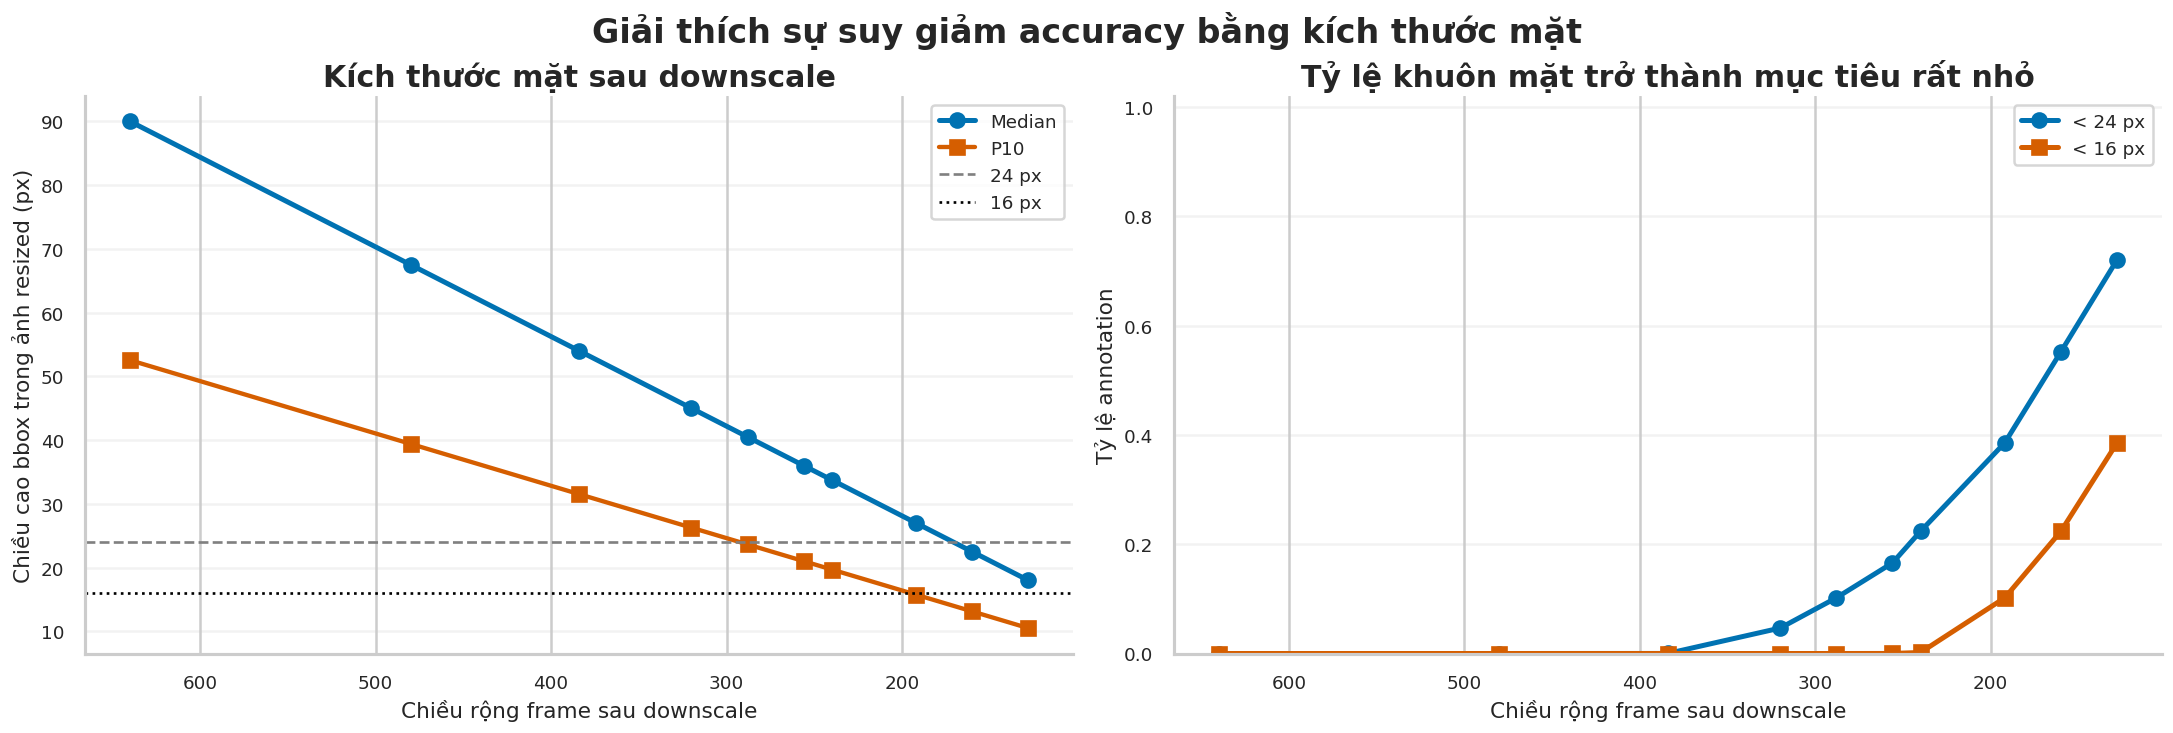

In [20]:
resolution_levels = (
    primary_res[["resolution_width", "resolution_height", "resolution_label"]]
    .drop_duplicates()
    .sort_values("resolution_width", ascending=False)
)

scale_rows = []
for row in resolution_levels.itertuples(index=False):
    factor = row.resolution_width / 800.0
    downscaled_face_h = manifest["box_h"] * factor
    downscaled_eye_d = manifest["eye_distance_px"] * factor
    scale_rows.append({
        "resolution_label": row.resolution_label,
        "resolution_width": row.resolution_width,
        "median_face_height_px": downscaled_face_h.median(),
        "p10_face_height_px": downscaled_face_h.quantile(0.10),
        "p90_face_height_px": downscaled_face_h.quantile(0.90),
        "median_eye_distance_px": downscaled_eye_d.median(),
        "share_face_height_lt_24px": (downscaled_face_h < 24).mean(),
        "share_face_height_lt_16px": (downscaled_face_h < 16).mean(),
    })

scale_df = pd.DataFrame(scale_rows)
display(scale_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
axes[0].plot(scale_df["resolution_width"], scale_df["median_face_height_px"], marker="o", linewidth=3, color="#0072B2", label="Median")
axes[0].plot(scale_df["resolution_width"], scale_df["p10_face_height_px"], marker="s", linewidth=2.6, color="#D55E00", label="P10")
axes[0].axhline(24, color="gray", linestyle="--", linewidth=1.6, label="24 px")
axes[0].axhline(16, color="black", linestyle=":", linewidth=1.6, label="16 px")
axes[0].set_title("Kích thước mặt sau downscale")
axes[0].set_xlabel("Chiều rộng frame sau downscale")
axes[0].set_ylabel("Chiều cao bbox trong ảnh resized (px)")
axes[0].invert_xaxis()
axes[0].legend(frameon=True)
style_axis(axes[0])

axes[1].plot(scale_df["resolution_width"], scale_df["share_face_height_lt_24px"], marker="o", linewidth=3, color="#0072B2", label="< 24 px")
axes[1].plot(scale_df["resolution_width"], scale_df["share_face_height_lt_16px"], marker="s", linewidth=3, color="#D55E00", label="< 16 px")
axes[1].set_title("Tỷ lệ khuôn mặt trở thành mục tiêu rất nhỏ")
axes[1].set_xlabel("Chiều rộng frame sau downscale")
axes[1].set_ylabel("Tỷ lệ annotation")
axes[1].set_ylim(0, 1.02)
axes[1].invert_xaxis()
axes[1].legend(frameon=True)
style_axis(axes[1])

fig.suptitle("Giải thích sự suy giảm accuracy bằng kích thước mặt", fontsize=20, fontweight="bold")
save_figure(fig, "12_face_scale_after_downscale")
plt.show()


,model,face_size_bucket,images,recall,mean_iou,median_conf,mean_eye_distance
0,SCRFD,small,709,0.9901,0.6301,0.8762,17.2167
1,SCRFD,medium,1209,0.9959,0.6183,0.8537,23.3288
2,SCRFD,large,1538,0.9974,0.6164,0.8899,31.5343
3,SCRFD,very_large,2220,0.9986,0.6200,0.8403,50.8060
4,YOLOv12n-FT,small,709,1.0000,0.8944,0.8790,17.2167
5,YOLOv12n-FT,medium,1209,1.0000,0.9093,0.8957,23.3288
6,YOLOv12n-FT,large,1538,1.0000,0.9304,0.9134,31.5343
7,YOLOv12n-FT,very_large,2220,1.0000,0.9409,0.9235,50.8060
8,YOLOv5n-FT,small,709,1.0000,0.8908,0.8850,17.2167
9,YOLOv5n-FT,medium,1209,1.0000,0.9160,0.8973,23.3288


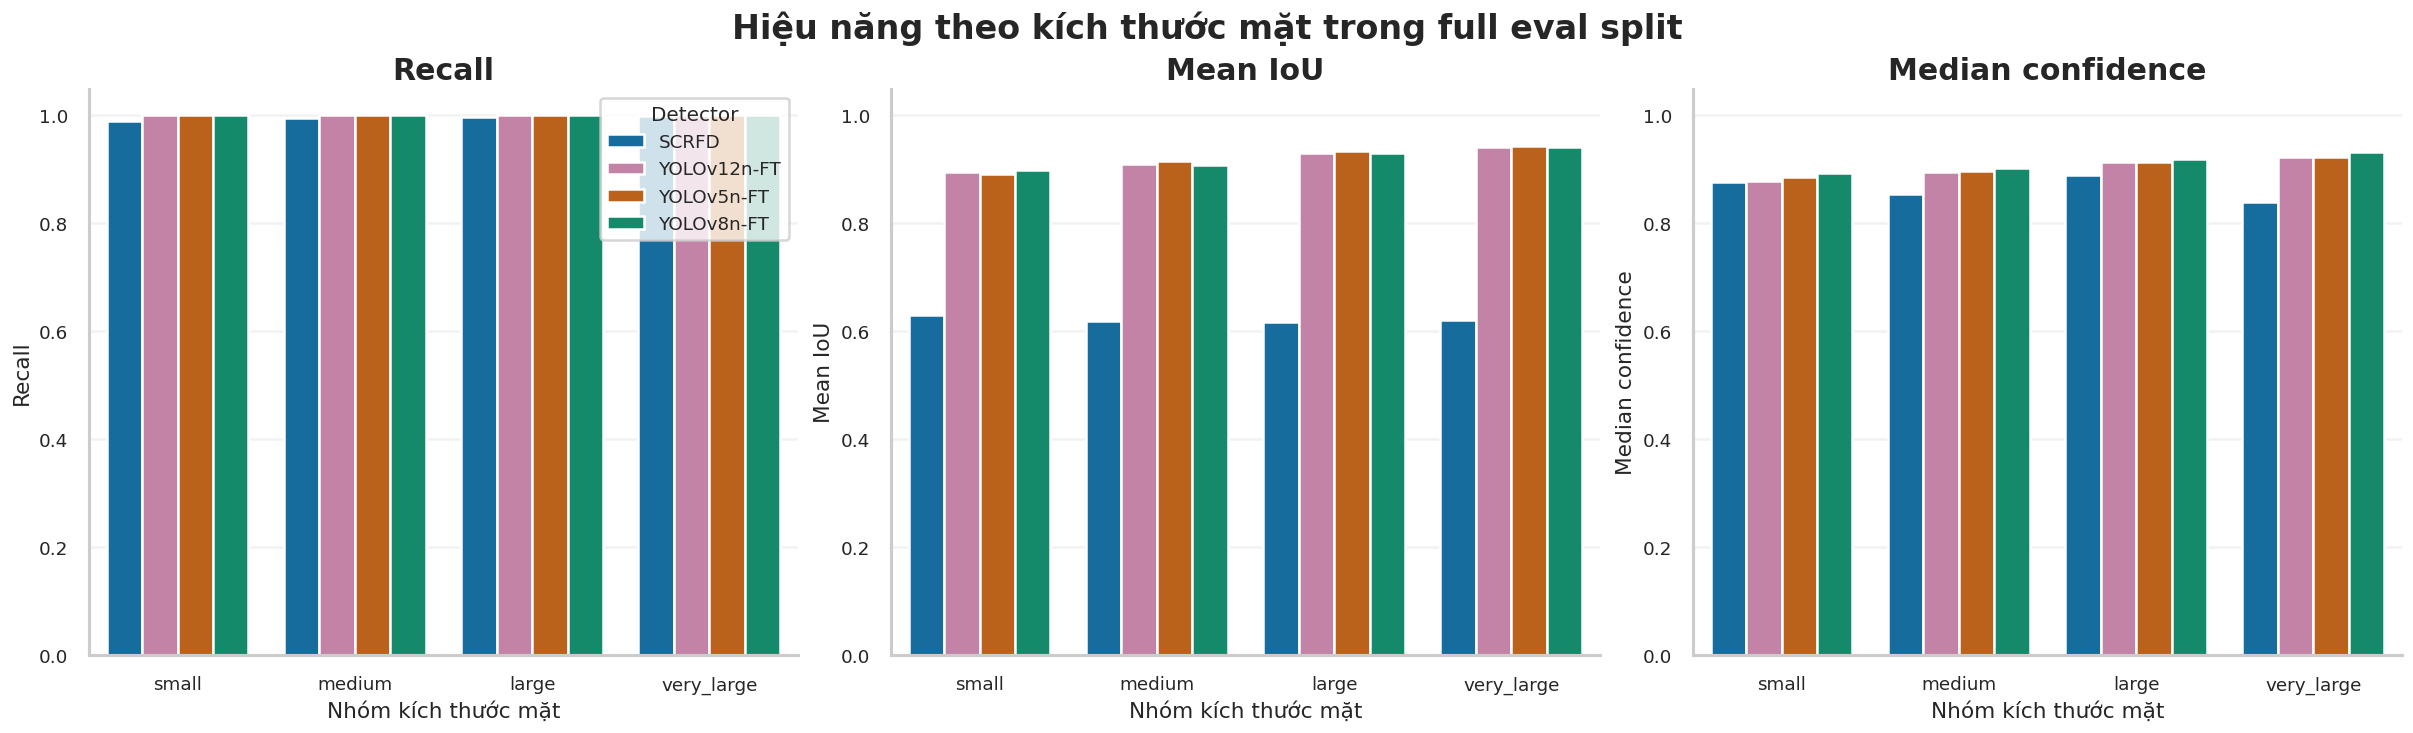

In [21]:
def box_iou(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)
    union = area_a + area_b - inter
    return inter / union if union else 0.0


gt = fixed_sample.copy()

all_match_frames = []
for model in MODEL_ORDER:
    model_preds = fixed_predictions[(fixed_predictions["model"] == model) & (fixed_predictions["conf"] >= PRIMARY_THRESHOLD)].copy()
    best_rows = []
    for row in gt.itertuples(index=False):
        preds = model_preds[model_preds["image_path"] == row.image_path]
        best_iou = 0.0
        best_conf = 0.0
        for pred in preds.itertuples(index=False):
            current_iou = box_iou([pred.x1, pred.y1, pred.x2, pred.y2], [row.x1, row.y1, row.x2, row.y2])
            if current_iou > best_iou:
                best_iou = current_iou
                best_conf = float(pred.conf)
        best_rows.append({
            "model": model,
            "image_path": row.image_path,
            "best_iou": best_iou,
            "best_conf": best_conf,
            "detected": best_iou >= IOU_THRESHOLD,
        })
    all_match_frames.append(gt.merge(pd.DataFrame(best_rows), on="image_path", how="left"))

match_df = pd.concat(all_match_frames, ignore_index=True)
match_df["face_size_bucket"] = pd.cut(
    match_df["eye_distance_px"],
    bins=[0, 20, 27, 37, 999],
    labels=["small", "medium", "large", "very_large"],
)

bucket_summary = match_df.groupby(["model", "face_size_bucket"], observed=False).agg(
    images=("image_path", "count"),
    recall=("detected", "mean"),
    mean_iou=("best_iou", "mean"),
    median_conf=("best_conf", "median"),
    mean_eye_distance=("eye_distance_px", "mean"),
).reset_index()

display(bucket_summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(20, 6), constrained_layout=True)
plot_info = [
    ("recall", "Recall", (0, 1.05)),
    ("mean_iou", "Mean IoU", (0, 1.05)),
    ("median_conf", "Median confidence", (0, 1.05)),
]
for ax, (metric, title, ylim) in zip(axes, plot_info):
    sns.barplot(data=bucket_summary, x="face_size_bucket", y=metric, hue="model", palette=MODEL_COLORS, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Nhóm kích thước mặt")
    ax.set_ylabel(title)
    ax.set_ylim(*ylim)
    style_axis(ax)
axes[0].legend(title="Detector", frameon=True)
axes[1].legend_.remove()
axes[2].legend_.remove()

fig.suptitle("Hiệu năng theo kích thước mặt trong full eval split", fontsize=20, fontweight="bold")
save_figure(fig, "13_hieu_nang_theo_kich_thuoc_mat")
plt.show()


,model,dataset,split,images,recall,mean_iou,median_conf,mean_eye_distance
0,SCRFD,P1E_S3_C3,eval,929,0.9957,0.6265,0.8605,45.2560
1,SCRFD,P1E_S4_C1,eval,1531,0.9980,0.6161,0.8647,36.1860
2,SCRFD,P1L_S3_C3,eval,1205,0.9967,0.6097,0.8693,36.4182
3,SCRFD,P1L_S4_C1,eval,2011,0.9960,0.6259,0.8747,30.0212
4,YOLOv12n-FT,P1E_S3_C3,eval,929,1.0000,0.9424,0.9231,45.2560
5,YOLOv12n-FT,P1E_S4_C1,eval,1531,1.0000,0.9231,0.9141,36.1860
6,YOLOv12n-FT,P1L_S3_C3,eval,1205,1.0000,0.9368,0.9184,36.4182
7,YOLOv12n-FT,P1L_S4_C1,eval,2011,1.0000,0.9128,0.8982,30.0212
8,YOLOv5n-FT,P1E_S3_C3,eval,929,1.0000,0.9458,0.9235,45.2560
9,YOLOv5n-FT,P1E_S4_C1,eval,1531,1.0000,0.9273,0.9130,36.1860


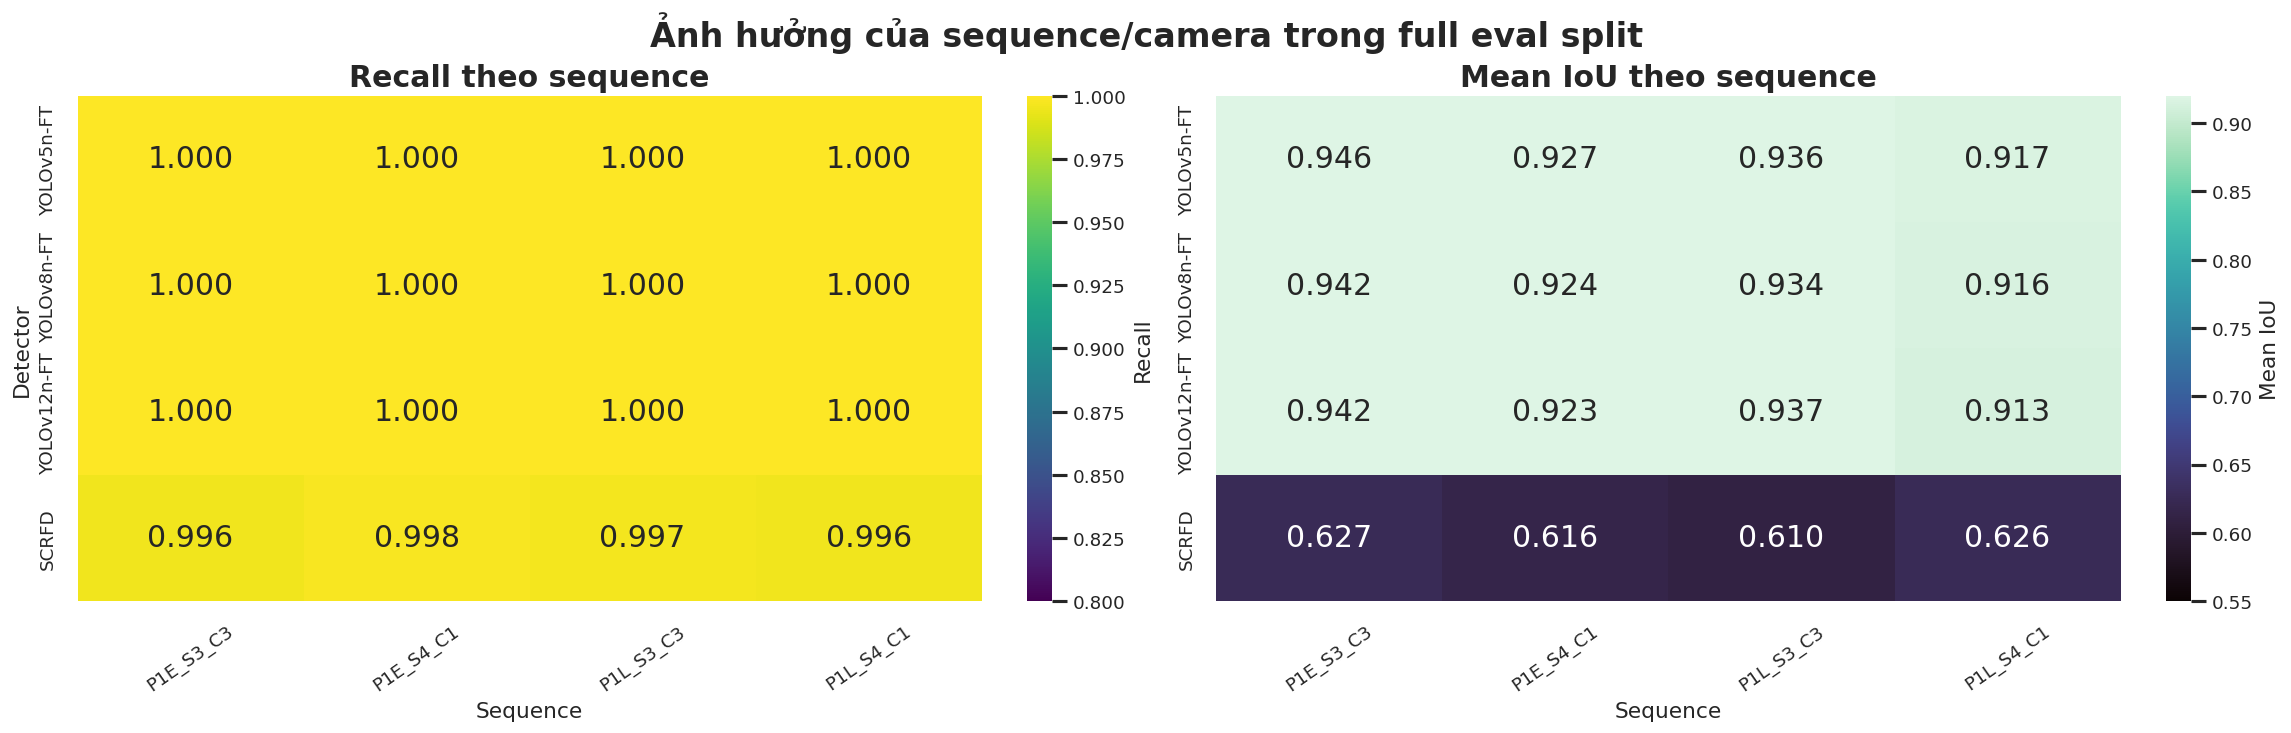

In [22]:
seq_perf = match_df.groupby(["model", "dataset", "split"]).agg(
    images=("image_path", "count"),
    recall=("detected", "mean"),
    mean_iou=("best_iou", "mean"),
    median_conf=("best_conf", "median"),
    mean_eye_distance=("eye_distance_px", "mean"),
).reset_index()

display(seq_perf.round(4))

sequence_order = seq_perf.sort_values("dataset")["dataset"].unique()
recall_by_sequence = (
    seq_perf.pivot(index="model", columns="dataset", values="recall")
    .reindex(index=MODEL_ORDER, columns=sequence_order)
)
iou_by_sequence = (
    seq_perf.pivot(index="model", columns="dataset", values="mean_iou")
    .reindex(index=MODEL_ORDER, columns=sequence_order)
)

fig, axes = plt.subplots(1, 2, figsize=(19, 6), constrained_layout=True)
sns.heatmap(recall_by_sequence, annot=True, fmt=".3f", cmap="viridis", vmin=0.80, vmax=1.0, ax=axes[0], cbar_kws={"label": "Recall"})
axes[0].set_title("Recall theo sequence")
axes[0].set_xlabel("Sequence")
axes[0].set_ylabel("Detector")
axes[0].tick_params(axis="x", rotation=35)

sns.heatmap(iou_by_sequence, annot=True, fmt=".3f", cmap="mako", vmin=0.55, vmax=0.92, ax=axes[1], cbar_kws={"label": "Mean IoU"})
axes[1].set_title("Mean IoU theo sequence")
axes[1].set_xlabel("Sequence")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=35)

fig.suptitle("Ảnh hưởng của sequence/camera trong full eval split", fontsize=20, fontweight="bold")
save_figure(fig, "14_hieu_nang_theo_sequence")
plt.show()


## 11. Kết luận vận hành cho Report 3

Kết quả sau fine-tune cho thấy YOLO nano có thể trở thành face detector cạnh tranh trên ChokePoint. Trước fine-tune, YOLO pretrained COCO không khớp bbox khuôn mặt; sau fine-tune, YOLOv5n-FT, YOLOv8n-FT và YOLOv12n-FT đều đạt AP50 cao và tạo ra đường cong resolution có ý nghĩa.

Ở benchmark cố định trên full eval split, SCRFD vẫn có F1 cao nhờ precision tốt, nhưng YOLO fine-tuned có AP50, recall và tốc độ cạnh tranh hơn đáng kể so với pretrained COCO. Ở resolution sweep, YOLO-FT đặc biệt mạnh trong vùng `320x240` đến `160x120`, cho thấy domain adaptation giúp detector học trực tiếp đặc trưng mặt trong bối cảnh ChokePoint.

Theo tiêu chí làm việc AP50 ≥ 0.95 và Recall ≥ 0.97, vùng `320x240` đến `240x180` vẫn là khuyến nghị vận hành bảo thủ. Một pipeline thực tế có thể chạy mặc định ở `320x240`, sau đó nâng lên `480x360` hoặc `640x480` khi confidence thấp, số mặt tăng đột biến hoặc bước recognition không đủ chắc chắn.


In [23]:
acceptable = model_curves[model_curves["acceptable"]].copy()
min_by_model = (
    acceptable.sort_values(["model", "resolution_width"], ascending=[True, True])
    .groupby("model", as_index=False)
    .head(1)
)
conservative = model_curves[model_curves["resolution_width"] == 320].copy()
decision_table = pd.concat([
    min_by_model.assign(Quyết_định="Mức thấp nhất đạt tiêu chí"),
    conservative.assign(Quyết_định="Khuyến nghị vận hành bảo thủ"),
], ignore_index=True)
decision_table = decision_table[[
    "Quyết_định", "model", "resolution_label", "ap50_voc101", "recall", "f1", "fps", "speedup_vs_640",
]].rename(columns={
    "Quyết_định": "Quyết định",
    "model": "Detector",
    "resolution_label": "Resolution",
    "ap50_voc101": "AP50",
    "recall": "Recall",
    "f1": "F1",
    "fps": "FPS",
    "speedup_vs_640": "Tăng tốc so với 640",
})
display(decision_table.round({"AP50": 4, "Recall": 4, "F1": 4, "FPS": 2, "Tăng tốc so với 640": 2}))


,Quyết định,Detector,Resolution,AP50,Recall,F1,FPS,Tăng tốc so với 640
0,Mức thấp nhất đạt tiêu chí,SCRFD,216p (288x216),0.9651,0.9783,0.9782,76.41,1.80
1,Mức thấp nhất đạt tiêu chí,YOLOv12n-FT,240p (320x240),0.9802,0.9801,0.9893,52.62,1.03
2,Mức thấp nhất đạt tiêu chí,YOLOv5n-FT,216p (288x216),0.9901,0.9937,0.9963,65.81,1.05
3,Mức thấp nhất đạt tiêu chí,YOLOv8n-FT,216p (288x216),0.9801,0.9813,0.9903,62.54,0.96
4,Khuyến nghị vận hành bảo thủ,YOLOv5n-FT,240p (320x240),0.9901,0.9991,0.9993,65.86,1.05
5,Khuyến nghị vận hành bảo thủ,YOLOv8n-FT,240p (320x240),0.9901,0.9967,0.9981,69.01,1.06
6,Khuyến nghị vận hành bảo thủ,YOLOv12n-FT,240p (320x240),0.9802,0.9801,0.9893,52.62,1.03
7,Khuyến nghị vận hành bảo thủ,SCRFD,240p (320x240),0.9637,0.9787,0.9778,80.36,1.90


## 12. Hướng mở rộng nghiên cứu

### 12.1 Mở rộng fine-tune YOLO

Report này đã fine-tune YOLOv5n, YOLOv8n và YOLOv12n trên subset ChokePoint face boxes để tạo benchmark công bằng hơn. Hướng mở rộng tiếp theo là train trên toàn bộ split `train_dev`, tăng số epoch, chạy bằng CUDA-enabled PyTorch, và đánh giá thêm seed khác để giảm rủi ro kết luận phụ thuộc vào sample.

### 12.2 Đánh giá recognition theo độ phân giải

Bước tiếp theo là thêm tầng nhận diện bằng ArcFace/InsightFace. Protocol có thể gồm: detect face, crop-align, trích xuất embedding, sau đó tính ROC, AUC, EER và TAR@FAR dựa trên `person_id`. Đây là phần trả lời câu hỏi lớn hơn: không chỉ phát hiện được mặt, mà crop đó còn đủ tốt để nhận diện danh tính hay không.

### 12.3 Inference thích nghi theo độ phân giải

Kết quả gợi ý rằng dùng một resolution cố định là chưa tối ưu. Hệ thống có thể chạy mặc định ở `240x180` hoặc `320x240`, sau đó tăng lên `480x360` hoặc `640x480` khi confidence thấp, face size nhỏ, số lượng mặt trong frame tăng hoặc recognition không đủ chắc chắn.

### 12.4 Gán nhãn bổ sung cho crowded frames

Các sequence đông người có giá trị cao cho stress test nhưng cần nhãn bổ sung để tính accuracy. Một hướng thực tế là pseudo-label bằng SCRFD high-confidence, sau đó audit thủ công bằng CVAT hoặc Label Studio. Phần này bám sát bài toán triển khai camera an ninh khi số lượng mặt trong khung hình tăng đột biến.

### 12.5 Tracking theo thời gian

Vì ChokePoint là dữ liệu video, tracking có thể giảm false negative ngắn hạn và ổn định crop đưa vào recognition. Paper có thể bổ sung cả frame-level metric và track-level metric để phản ánh tốt hơn pipeline camera liên tục.


## 13. Danh sách biểu đồ đã xuất

Tất cả biểu đồ trong notebook được lưu đồng thời ở định dạng `.png` và `.pdf` trong thư mục `chokepoint_data/modeling/report3_figures`. File `.png` phù hợp để chèn nhanh vào report, trong khi `.pdf` phù hợp hơn cho bản paper vì giữ được chất lượng vector khi phóng to.


In [24]:
figures_df = pd.DataFrame(SAVED_FIGURES)
display(figures_df)
print(f"Đã lưu {len(figures_df)} biểu đồ vào: {FIGURE_DIR}")


,Tên hình,PNG,PDF
0,report3_01_phan_bo_du_lieu,chokepoint_data\modeling\report3_figures\repor...,chokepoint_data\modeling\report3_figures\repor...
1,report3_02_phan_bo_kich_thuoc_mat,chokepoint_data\modeling\report3_figures\repor...,chokepoint_data\modeling\report3_figures\repor...
2,report3_03_vi_du_nhan_bbox_tu_mat,chokepoint_data\modeling\report3_figures\repor...,chokepoint_data\modeling\report3_figures\repor...
3,report3_04_yolo_before_after_finetune,chokepoint_data\modeling\report3_figures\repor...,chokepoint_data\modeling\report3_figures\repor...
4,report3_05_benchmark_nen_full_eval,chokepoint_data\modeling\report3_figures\repor...,chokepoint_data\modeling\report3_figures\repor...
5,report3_06_detector_resolution_curves,chokepoint_data\modeling\report3_figures\repor...,chokepoint_data\modeling\report3_figures\repor...
6,report3_07_tradeoff_accuracy_speed,chokepoint_data\modeling\report3_figures\repor...,chokepoint_data\modeling\report3_figures\repor...
7,report3_08_heatmap_model_resolution,chokepoint_data\modeling\report3_figures\repor...,chokepoint_data\modeling\report3_figures\repor...
8,report3_09_heatmap_threshold_all_detectors,chokepoint_data\modeling\report3_figures\repor...,chokepoint_data\modeling\report3_figures\repor...
9,report3_10_threshold_precision_recall_f1,chokepoint_data\modeling\report3_figures\repor...,chokepoint_data\modeling\report3_figures\repor...


Đã lưu 14 biểu đồ vào: D:\Admin\Download\DSP391m\chokepoint_data\modeling\report3_figures


## Tài liệu tham khảo

- ChokePoint Dataset official page: https://arma.sourceforge.net/chokepoint/
- Wong, Y., Chen, S., Mau, S., Sanderson, C., & Lovell, B. C. (2011). Patch-based Probabilistic Image Quality Assessment for Face Selection and Improved Video-based Face Recognition.
- Guo, J., Deng, J., Lattas, A., & Zafeiriou, S. (2021). Sample and Computation Redistribution for Efficient Face Detection (SCRFD). https://arxiv.org/abs/2105.04714
- Ultralytics YOLOv5 documentation: https://docs.ultralytics.com/models/yolov5/
- Ultralytics YOLOv8 documentation: https://docs.ultralytics.com/models/yolov8/
- YOLO12 / YOLOv12 documentation and paper: https://docs.ultralytics.com/models/yolo12/ and https://arxiv.org/abs/2502.12524
- Seaborn documentation, Choosing color palettes: https://seaborn.pydata.org/tutorial/color_palettes.html
- Matplotlib documentation, Choosing Colormaps: https://matplotlib.org/stable/users/explain/colors/colormaps.html
- ColorBrewer: https://colorbrewer2.org/


### - Có thể v12 trade off độ chính xác và tốc độ để nhận diện nhiều mặt trong 1 frame hơn
### - Có thể fine-tune đang chưa phù hợp cho v12